# Features and adaptive windows

Explore microstructure facts, adaptive lookbacks, rank-like features, slopes, event thresholds and event fractions.

**Part 1/3 of a shared-state notebook series.** This part uses variables/functions from earlier parts. Opening another notebook normally creates a new kernel. Use `python scripts/run_series.py microstructure --export outputs/microstructure_combined.ipynb` from the repository root, then open the exported notebook for interactive execution. Exporting does not execute the research or restore missing data.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Micro Structure.ipynb`, original cells 0–196 (zero-based).


In [ ]:
from pathlib import Path
import os
import sys

# Locate the repository from its root or any notebook subdirectory.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "tradinguni_paths.py").is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from inside the TradingUni repository.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from tradinguni_paths import data_path, output_path
os.chdir(REPO_ROOT)


# Load Data

In [1]:
import polars as pl

aggbars2020 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2020.parquet")))
aggbars2021 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2021.parquet")))
aggbars2022 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2022.parquet")))
aggbars2023 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2023.parquet")))
aggbars2024 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2024.parquet")))
aggbars2025 = pl.read_parquet(str(data_path("0.Data -> Facts/Binance Vision Data/aggBars/aggBars-1m-ETH-2025.parquet")))

aggbars = pl.concat([aggbars2020, aggbars2021, aggbars2022, aggbars2023, aggbars2024, aggbars2025])

In [2]:
aggbars

t,open,high,low,close,vol_base,vol_quote,trade_count,buy_count,sell_count,buy_quote,sell_quote,signed_quote,vwap,trade_rate,imbalance,range,hl_pct,prev_close,ret_inbar,ret_cc,gap_oc,dt_mean_ms,dt_median_ms,dt_p90_ms,frac_dt0,active_ms,intensity_peak_1s,realized_var_inbar,dp0_frac,n_price_changes,up_ticks,down_ticks,max_up_move,max_down_move,n_returns,avg_trade_q,avg_trade_notional,q_p50,q_p90,q_p99,notional_p90,notional_p99,top1_share,sign_persistence_inbar,flip_count,sign_entropy,n_trans,run_max,run_mean,is_sparse_stats,is_sparse_seq,is_sparse_top1,gap_ms_from_last_trade,is_no_trade_fill,is_missing_fill
datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,f64,f64,u32,u32,u32,f64,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,i32,i64,f64,bool,bool,bool,i64,bool,bool
2020-01-01 00:00:00,129.16,129.19,128.96,129.02,305.44687,39416.984623,90.0,27.0,63.0,12240.154502,27176.830121,-14936.675619,129.046942,1.5,-0.37894,0.23,0.001782,null,-0.001085,null,null,653.370787,260.0,1765.0,0.033708,87,7,0.000002,0.539326,41,16,25,0.06,-0.06,89,3.393854,437.966496,1.00526,7.70228,19.36258,993.748166,2499.128201,0.232843,0.764045,21,1.126515,89,27,4.090909,false,false,false,0,false,false
2020-01-01 00:01:00,128.99,129.11,128.99,129.02,118.00168,15228.324945,39.0,16.0,23.0,9995.54286,5232.782085,4762.760775,129.051764,0.65,0.312757,0.12,0.00093,129.02,0.000233,0.0,-0.000233,1428.289474,538.5,3537.0,0.078947,36,9,3.6627e-7,0.5,19,11,8,0.03,-0.03,38,3.025684,390.46987,0.31116,5.0,51.0,645.1,6580.53,null,0.631579,14,1.331309,38,13,2.6,false,false,true,0,false,false
2020-01-01 00:02:00,129.0,129.05,128.94,128.98,141.64707,18268.673987,37.0,19.0,18.0,16285.746282,1982.927705,14302.818578,128.973187,0.616667,0.782915,0.11,0.000853,129.02,-0.000155,-0.00031,-0.000155,1629.222222,970.5,4154.0,0.055556,35,5,9.1361e-7,0.25,27,13,14,0.05,-0.05,36,3.828299,493.747946,0.62237,19.0,19.38736,2450.81,2500.097226,null,0.75,9,1.253421,36,8,3.7,false,false,true,0,false,false
2020-01-01 00:03:00,128.95,129.02,128.94,128.98,29.11515,3755.064313,34.0,17.0,17.0,2057.377643,1697.686671,359.690972,128.972865,0.566667,0.095788,0.08,0.00062,128.98,0.000233,0.0,-0.000233,1763.181818,1261.0,4452.0,0.030303,33,5,6.4318e-7,0.393939,20,11,9,0.05,-0.05,33,0.856328,110.443068,0.328,2.0,8.0,257.92,1031.68,null,0.575758,14,1.373974,33,5,2.266667,false,false,true,0,false,false
2020-01-01 00:04:00,128.97,128.97,128.8,128.88,102.50335,13209.658272,52.0,25.0,27.0,7735.141044,5474.517228,2260.623816,128.870503,0.866667,0.171134,0.17,0.001319,128.98,-0.000698,-0.000776,-0.000078,1124.313725,305.0,3804.0,0.196078,42,9,0.000001,0.352941,33,13,20,0.05,-0.04,51,1.971218,254.03189,0.62262,3.49697,18.84797,450.899312,2428.372455,0.390877,0.745098,13,1.259017,51,11,3.714286,false,false,false,0,false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.14,2971.82,2971.13,2971.82,22.8505,67897.53557,139.0,117.0,22.0,64144.830718,3752.704852,60392.125866,2971.380739,2.316667,0.88946,0.69,0.000232,2971.13,0.000229,0.000232,0.000003,430.536232,1.0,1357.0,0.456522,76,45,1.6535e-9,0.449275,76,64,12,0.04,-0.01,138,0.164392,488.471479,0.0253,0.467,1.6908,1387.52238,5023.603512,0.152019,0.811594,26,0.841451,138,48,5.148148,false,false,false,0,false,false
2025-12-31 23:56:00,2971.82,2972.83,2971.81,2972.82,43.2258,128485.978662,193.0,170.0,23.0,98075.314425,30410.664237,67664.650188,2972.437263,3.216667,0.526631,1.02,0.000343,2971.82,0.000336,0.000336,0.0,302.208333,0.0,1015.0,0.526042,92,31,2.2411e-9,0.458333,104,91,13,0.04,-0.01,192,0.223968,665.730459,0.027,0.466,2.4086,1385.3015,7160.334252,0.239496,0.859375,27,0.685393,192,75,6.892857,false,false,false,0,false,false
2025-12-31 23:57:00,2972.83,2972.83,2971.64,2971.64,61.2318,181999.692974,181.0,43.0,138.0,65231.280412,116768.412562,-51537.13215,2972.306758,3.016667,-0.283172,1.19,0.0004,2

In [ ]:
df = aggbars.with_columns([
    pl.when(pl.col("realized_var_inbar").is_not_null())
          .then(pl.col("realized_var_inbar").clip(lower_bound=0.0).sqrt())
          .otherwise(None)
          .alias("rv_sqrt"),
    pl.when(pl.col("flip_count").is_not_null())
          .then(pl.col("flip_count") / pl.col("n_trans"))
          .otherwise(None)
          .alias("flip_rate")
])

In [ ]:
df_Feature = df.select([
    "t",
    "close",
    "active_ms",
    "flip_rate",
    "avg_trade_q",
    "run_mean",

    "signed_quote",

    "rv_sqrt",
    "run_max",
    "intensity_peak_1s"
])

# EDA Data

In [ ]:
# .select([
#  't',
#  'close',
#  'vol_quote',
#  'trade_count',
#  'buy_count',
#  'sell_count',
#  'buy_quote',
#  'sell_quote',
#  'signed_quote',
#  'active_ms',
#  'intensity_peak_1s',
#  'realized_var_inbar',
#  'n_price_changes',
#  'up_ticks',
#  'down_ticks',
#  'max_up_move',
#  'max_down_move',
#  'avg_trade_q',
#  'flip_count',
#  'n_trans',
#  'run_max',
#  'run_mean'
# ])

## plot time series

In [ ]:
import polars as pl
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

def _to_dt(x):
    if x is None:
        return None
    return pd.to_datetime(x).to_pydatetime()

def plot_panes(
    df: pl.DataFrame,
    panes,                    # list[list[str]] เช่น [["close"], ["rk_V_slow","V_mean_60m"], ["I_spike","V_xhi"]]
    pane_titles=None,         # list[str] ชื่อช่อง (optional)
    start=None,
    end=None,
    time_col="t",
    auto_max_points=1200000,
    shared_x=True,
    height_per_pane=220,
    show_pane_line_names=True,# << แสดงรายชื่อเส้นในมุมของแต่ละ pane
    pane_line_names_max=6,    # ถ้าเส้นเยอะ จะตัดให้ไม่รก
):
    dff = df.sort(time_col)

    start_dt, end_dt = _to_dt(start), _to_dt(end)
    if start_dt is not None:
        dff = dff.filter(pl.col(time_col) >= pl.lit(start_dt))
    if end_dt is not None:
        dff = dff.filter(pl.col(time_col) <= pl.lit(end_dt))

    # รวมทุกคอลัมน์ที่ต้องใช้
    need_cols = {time_col}
    for pane in panes:
        for c in pane:
            need_cols.add(c)
    need_cols = [c for c in need_cols if c in dff.columns]
    dff = dff.select(need_cols)

    n = dff.height
    if n == 0:
        print("No data in selected range")
        return

    # auto downsample
    step = max(1, n // auto_max_points)
    if step > 1:
        dff = dff.with_row_index("idx").filter(pl.col("idx") % step == 0).drop("idx")

    pdf = dff.to_pandas()

    rows = len(panes)

    # default pane titles
    if pane_titles is None:
        pane_titles = [f"Pane {i}" for i in range(1, rows + 1)]
    if len(pane_titles) != rows:
        raise ValueError(f"pane_titles length must equal number of panes ({rows})")

    fig = make_subplots(
        rows=rows, cols=1,
        shared_xaxes=shared_x,
        vertical_spacing=0.03,
        subplot_titles=pane_titles
    )

    # เก็บชื่อเส้นที่ใส่จริงต่อ pane (เผื่อบางคอลัมน์ไม่มี)
    pane_used = [[] for _ in range(rows)]

    for i, pane_cols in enumerate(panes, start=1):
        for c in pane_cols:
            if c not in pdf.columns:
                continue
            fig.add_trace(
                go.Scatter(x=pdf[time_col], y=pdf[c], name=c, mode="lines"),
                row=i, col=1
            )
            pane_used[i-1].append(c)

    # rangeslider แถวล่าง
    fig.update_xaxes(type="date", rangeslider=dict(visible=False), row=rows, col=1)

    fig.update_layout(
        height=height_per_pane * rows + 120,
        hovermode="x unified",
        legend=dict(orientation="h")
    )

    # ---- ใส่รายชื่อเส้นไว้ “มุมซ้ายบน” ของแต่ละ pane ----
    if show_pane_line_names:
        for i in range(1, rows + 1):
            names = pane_used[i-1]
            if not names:
                continue

            shown = names[:pane_line_names_max]
            more = f" (+{len(names)-len(shown)} more)" if len(names) > len(shown) else ""
            text = " | ".join(shown) + more

            # domain ของแกน y ใน row นี้ (ตำแหน่งแนวตั้งของ pane)
            yaxis_name = "yaxis" if i == 1 else f"yaxis{i}"
            dom = fig.layout[yaxis_name].domain  # (y0, y1)

            # วางข้อความใน paper coords: x ใกล้ซ้าย, y ใกล้บนของ domain
            fig.add_annotation(
                x=0.01, y=dom[1] - 0.01,
                xref="paper", yref="paper",
                text=text,
                showarrow=False,
                align="left",
                font=dict(size=12),
                bgcolor="rgba(255,255,255,0.6)",
                bordercolor="rgba(0,0,0,0.15)",
                borderwidth=1,
                borderpad=3
            )

    display(fig)

def plot_range(df, panes, t0, t1):
    # t0/t1 เป็น string ก็ได้
    plot_panes(df, panes, start=t0, end=t1)  # ใช้ plot_panes ที่ทำไว้ก่อนหน้า

In [ ]:
df.columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'signed_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'active_ms',
 'intensity_peak_1s',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_q',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'run_max',
 'run_mean',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill']

In [ ]:
panes = [
    ["close"],
    ["avg_trade_q"],
    ["active_ms"],
    # ["realized_var_inbar"],
    ["rv_sqrt"],

    # ["flip_count"],
    # ["n_trans"],
    ["flip_rate"],

    ["run_mean"],
    ["run_max"],
    ["intensity_peak_1s"],
    ["signed_quote"],
]
plot_range(df, panes, "2024-01-07", "2024-01-09")

In [ ]:
df.select(["run_mean","flip_rate"]).to_pandas().dropna().corr()

,run_mean,flip_rate
run_mean,1.000000,-0.790585
flip_rate,-0.790585,1.000000


In [ ]:
df.select(["n_trans","active_ms","flip_count","flip_rate"]).to_pandas().dropna().corr()

,n_trans,active_ms,flip_count,flip_rate
n_trans,1.000000,0.910421,0.828991,-0.381666
active_ms,0.910421,1.000000,0.935929,-0.264343
flip_count,0.828991,0.935929,1.000000,-0.087563
flip_rate,-0.381666,-0.264343,-0.087563,1.000000


## Distribution

In [ ]:
cols = [
    "t",
    "close",
    "vol_quote",
    "signed_quote",
    "avg_trade_q",
    "realized_var_inbar",
    "flip_count",
    "active_ms",
    "n_trans",
    "run_mean",
    "run_max",
    "intensity_peak_1s"
]

In [ ]:
df2 = df.select(cols).to_pandas()

In [ ]:
df2.head()

,t,close,vol_quote,signed_quote,avg_trade_q,realized_var_inbar,flip_count,active_ms,n_trans,run_mean,run_max,intensity_peak_1s
0,2020-01-01 00:00:00,129.02,39416.984623,-14936.675619,3.393854,1.680855e-06,21.0,87.0,89.0,4.090909,27.0,7.0
1,2020-01-01 00:01:00,129.02,15228.324945,4762.760775,3.025684,3.662717e-07,14.0,36.0,38.0,2.600000,13.0,9.0
2,2020-01-01 00:02:00,128.98,18268.673987,14302.818578,3.828299,9.136136e-07,9.0,35.0,36.0,3.700000,8.0,5.0
3,2020-01-01 00:03:00,128.98,3755.064313,359.690972,0.856328,6.431817e-07,14.0,33.0,33.0,2.266667,5.0,5.0
4,2020-01-01 00:04:00,128.88,13209.658272,2260.623816,1.971218,1.137804e-06,13.0,42.0,51.0,3.714286,11.0,9.0


### Global Dist.

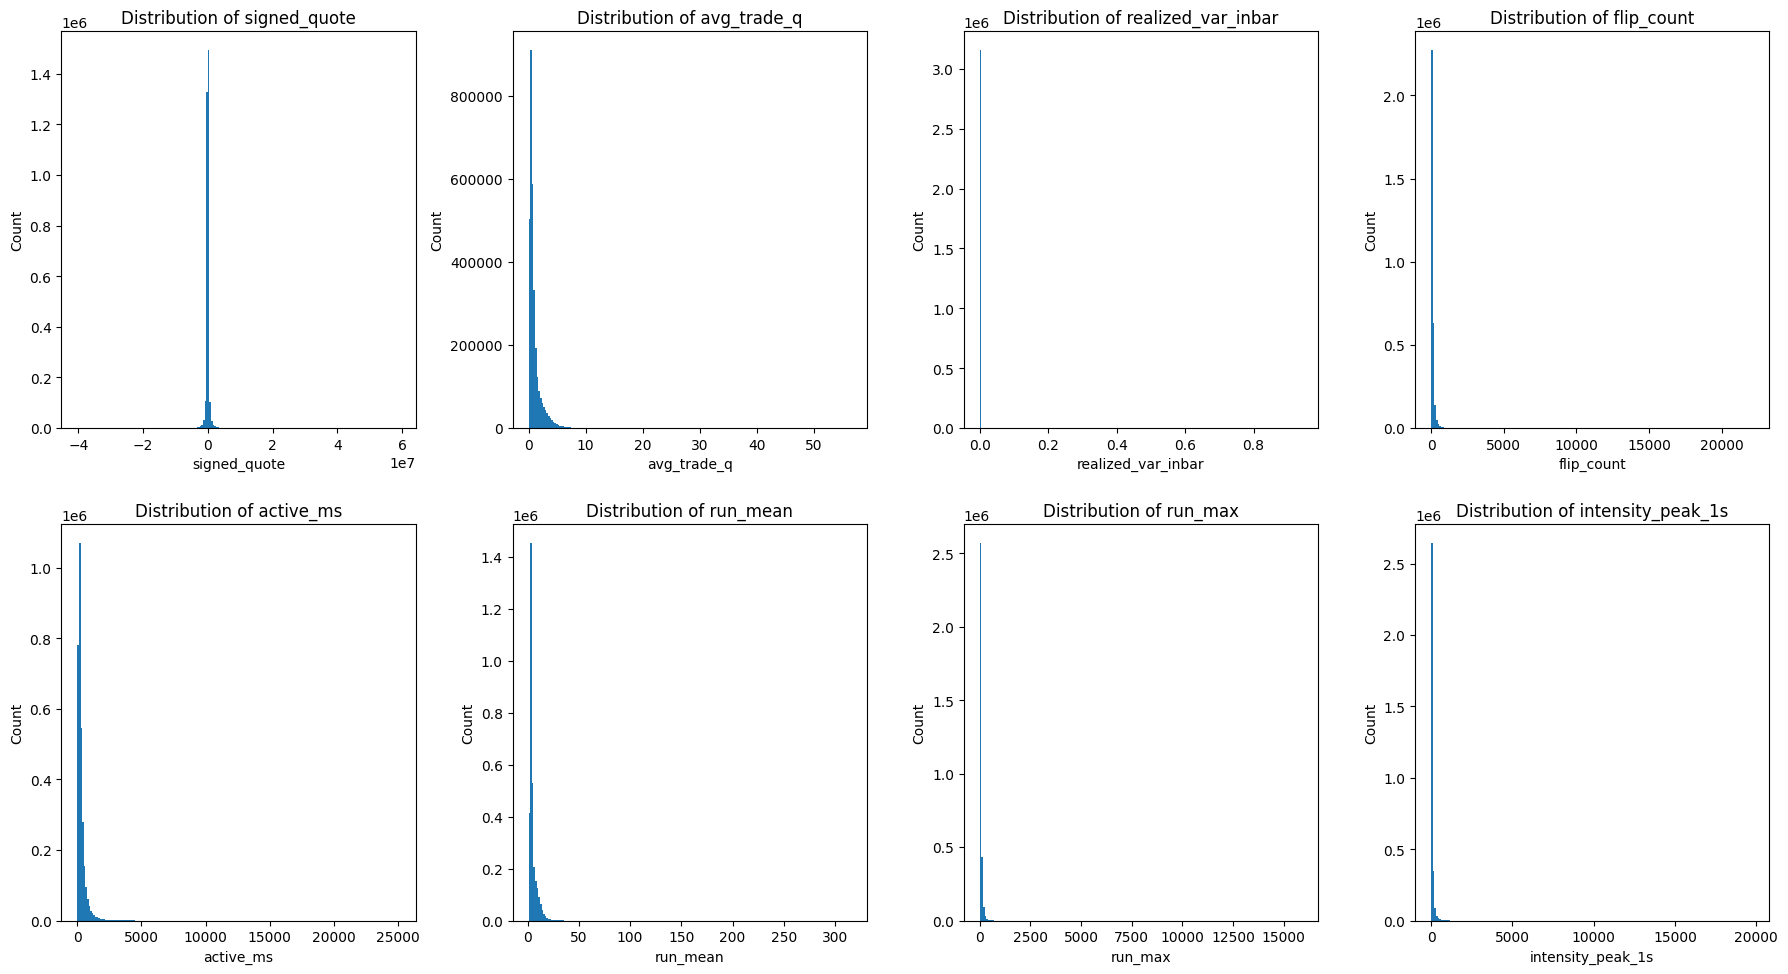

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cols = [
    "signed_quote",
    "avg_trade_q",
    "realized_var_inbar",
    "flip_count",
    "active_ms",
    "run_mean",
    "run_max",
    "intensity_peak_1s"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for ax, c in zip(axes, cols):
    data = df.select(c).to_series().drop_nulls().to_numpy()

    ax.set_title(f"Distribution of {c}")
    ax.hist(data, bins=200)
    ax.set_xlabel(c)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

**heavy-tailed**
- zero / near-zero mass
- event-driven
- เหมาะกับ rank / quantile / event-fraction / regime logic

In [ ]:
df2["flip_rate"] = df2["flip_count"]/df2["n_trans"]

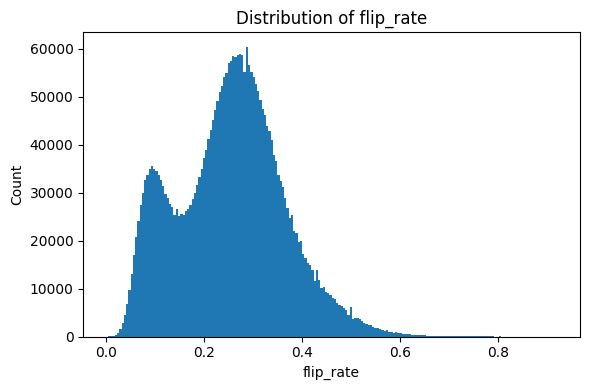

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

c = "flip_rate"
data = df2[c].dropna().to_numpy()

ax.set_title(f"Distribution of {c}")
ax.hist(data, bins=200)
ax.set_xlabel(c)
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [ ]:
df2["imbalance_quote"] = df2["signed_quote"]/df2["vol_quote"]

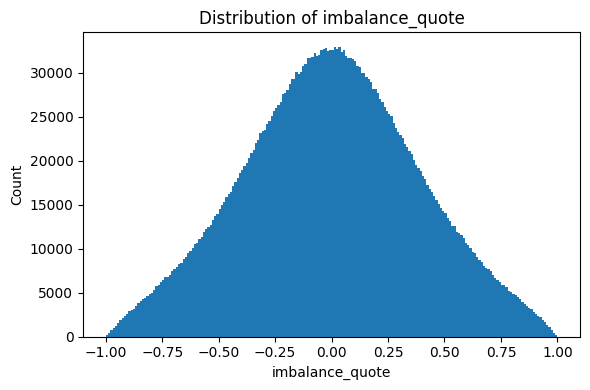

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

c = "imbalance_quote"
data = df2[c].dropna().to_numpy()

ax.set_title(f"Distribution of {c}")
ax.hist(data, bins=200)
ax.set_xlabel(c)
ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

### Local Dist.

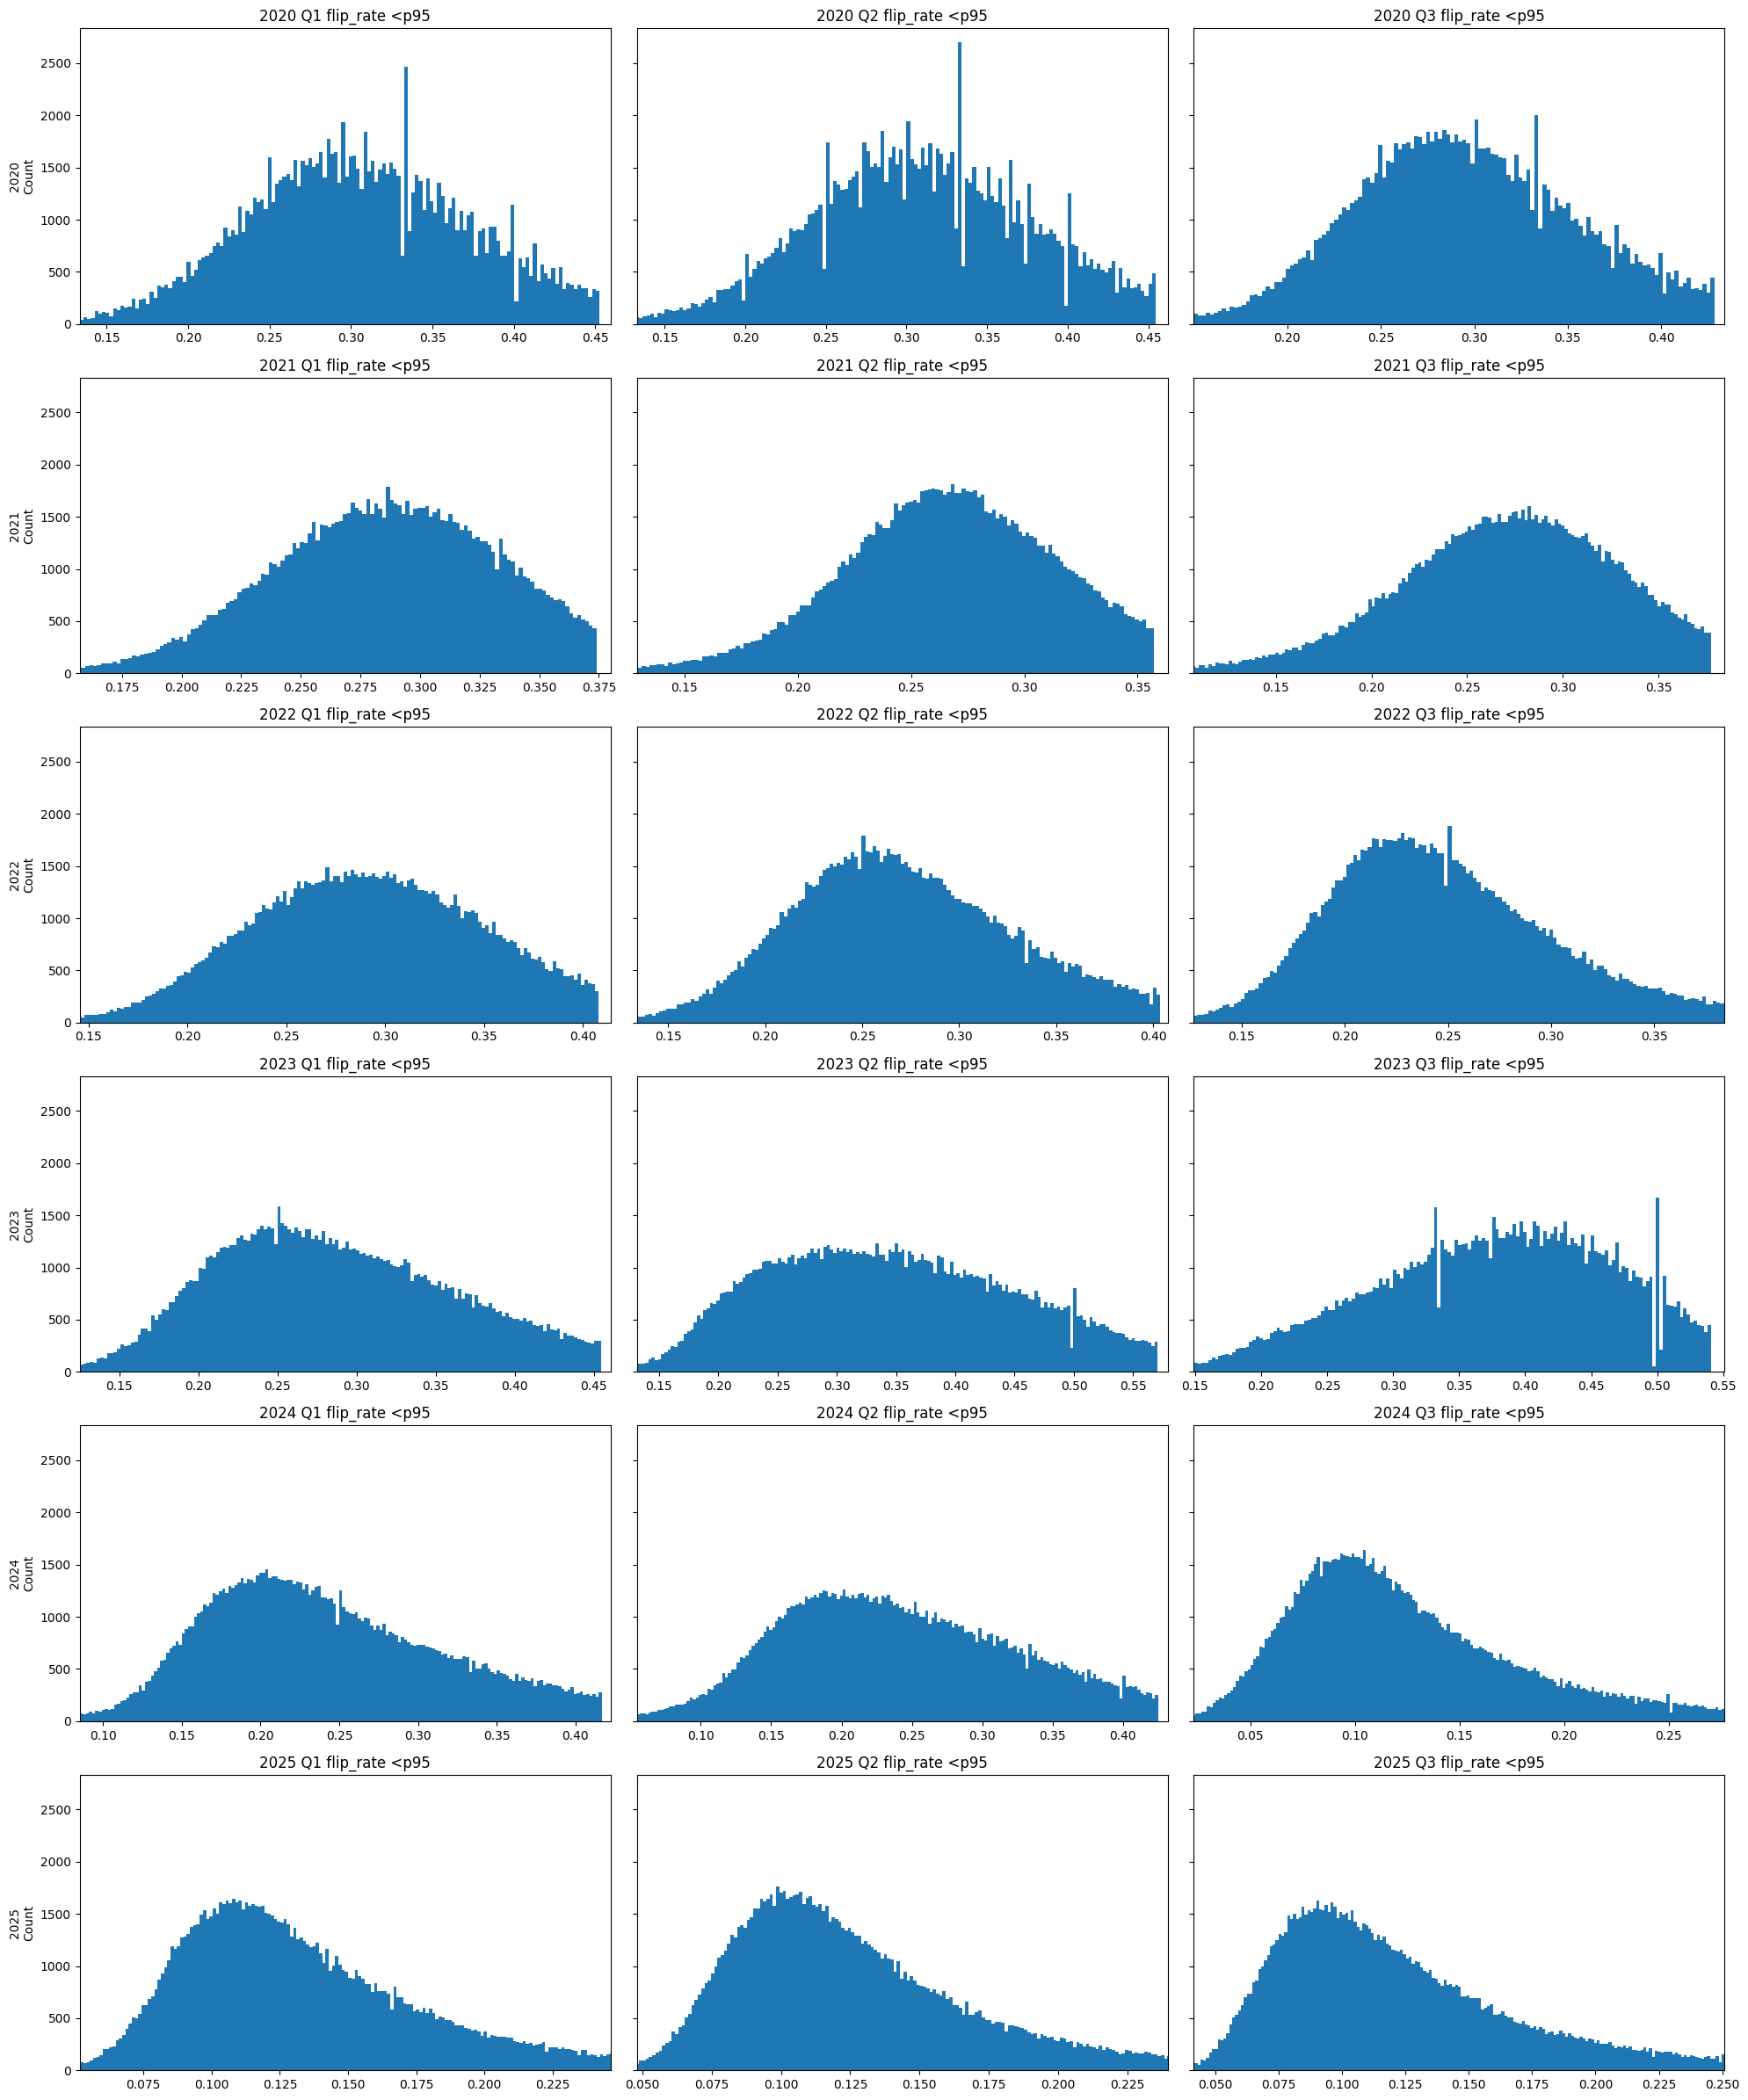

In [ ]:
import matplotlib.pyplot as plt
import polars as pl

years = [2020, 2021, 2022, 2023, 2024, 2025]
quarters = [1, 2, 3]

col = "flip_rate"

fig, axes = plt.subplots(
    len(years), len(quarters),
    figsize=(20, 4 * len(years)),
    sharey=True,
    sharex=False  # สำคัญ: ให้แต่ละ subplot มีแกน X ของตัวเอง
)

for i, y in enumerate(years):
    for j, q in enumerate(quarters):

        ax = axes[i, j]

        df_yq = df.filter(
            (pl.col("t").dt.year() == y) &
            (pl.col("t").dt.quarter() == q)
        )

        if df_yq.height == 0:
            ax.set_visible(False)
            continue

        # ตัด outlier ด้วย p95 เหมือนเดิม
        p95 = df_yq.select(pl.col(col).quantile(0.95)).item()
        # p05 = df_yq.select(pl.col(col).quantile(0.05)).item()

        s = (
            df_yq
            .filter(pl.col(col) <= p95)
            # .filter(pl.col(col) >= p05)
            .select(col)
            .drop_nulls()
            .to_series()
        )

        if s.len() == 0:
            ax.set_visible(False)
            continue

        data = s.to_numpy()

        # ปรับสเกลแกน X ให้เหมาะกับข้อมูลใน subplot นี้
        # ใช้ q01-q99 เพื่อกันหางสุด ๆ ทำให้ zoom ดู shape ชัดขึ้น
        x_lo = s.quantile(0.01)
        x_hi = s.quantile(0.99)

        # เผื่อกรณีข้อมูลแคบมาก/ค่าคงที่
        if x_lo == x_hi:
            pad = 1e-9 if x_lo == 0 else abs(x_lo) * 0.01
            x_lo -= pad
            x_hi += pad
        else:
            pad = (x_hi - x_lo) * 0.05
            x_lo -= pad
            x_hi += pad

        ax.hist(data, bins=200)
        ax.set_xlim(float(x_lo), float(x_hi))
        ax.set_title(f"{y} Q{q} {col} <p95")

        # ให้ทุก subplot โชว์ตัวเลขแกน X ของตัวเอง
        ax.tick_params(axis="x", labelbottom=True)

    axes[i, 0].set_ylabel(f"{y}\nCount")

plt.tight_layout()
plt.show()

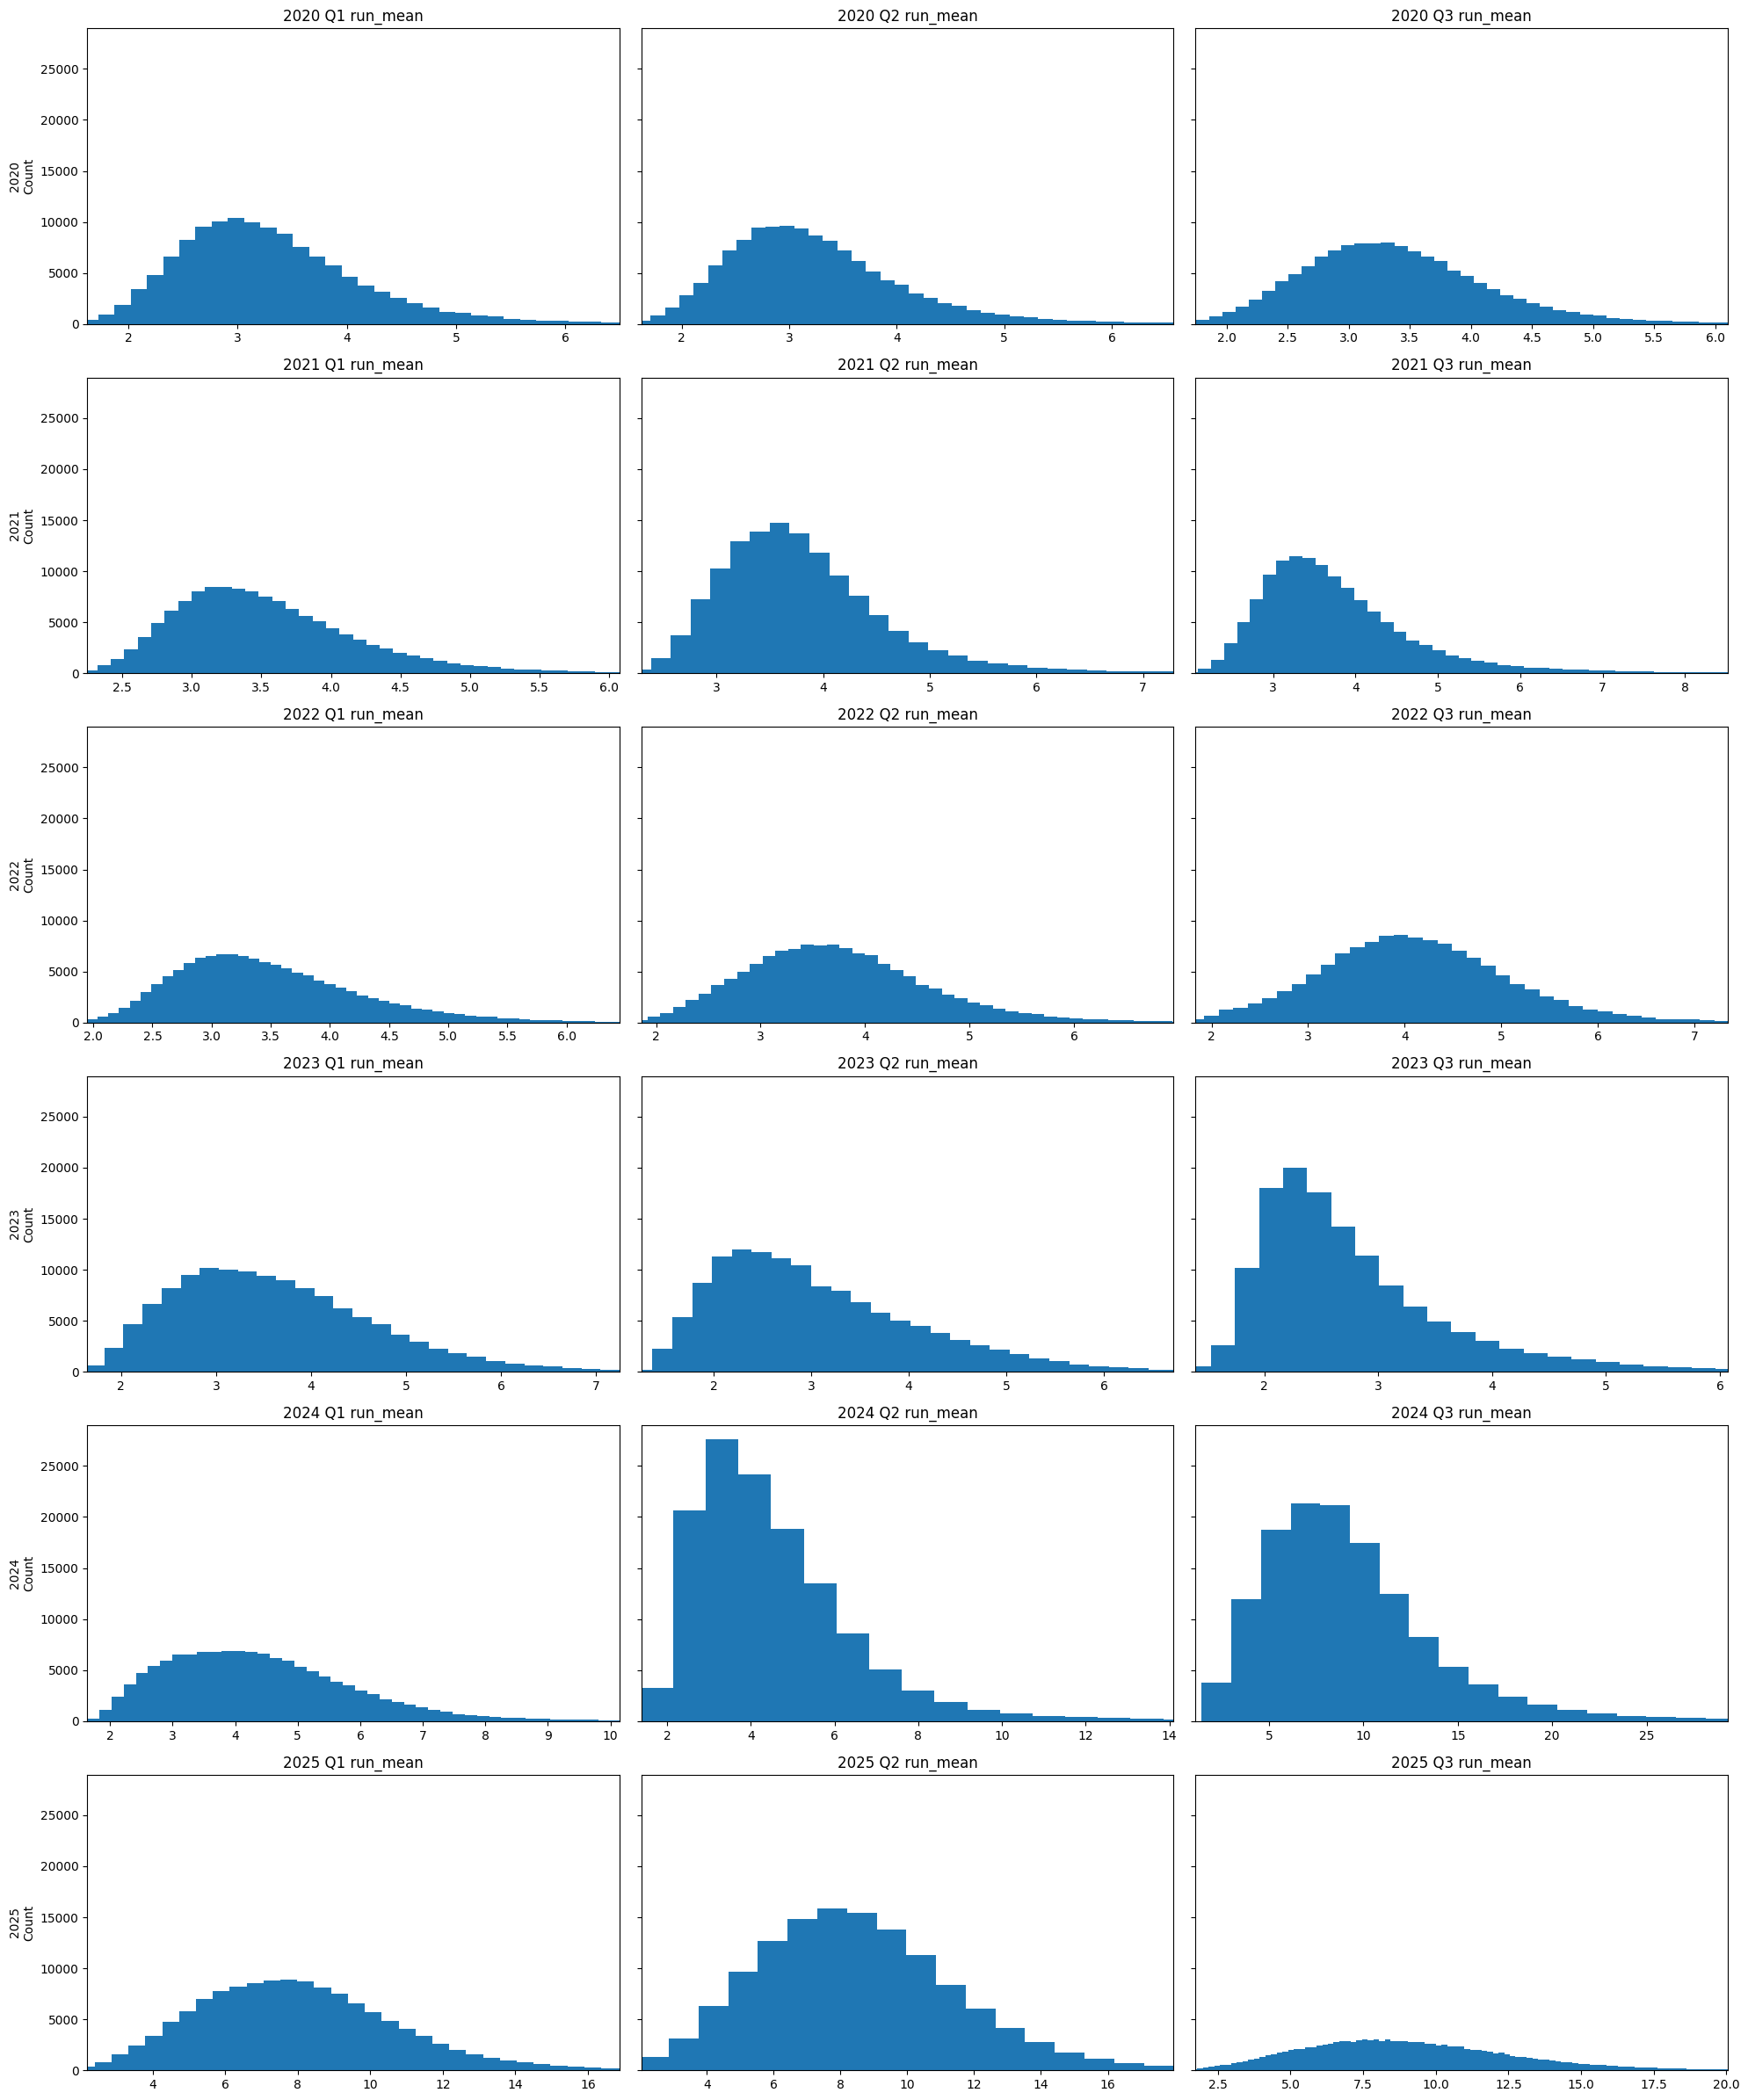

In [ ]:
years = [2020, 2021, 2022, 2023, 2024, 2025]
quarters = [1, 2, 3]

col = "run_mean"

fig, axes = plt.subplots(
    len(years), len(quarters),
    figsize=(20, 4 * len(years)),
    sharey=True,
    sharex=False
)

for i, y in enumerate(years):
    for j, q in enumerate(quarters):

        ax = axes[i, j]

        df_yq = df2[
            (df2["t"].dt.year == y) &
            (df2["t"].dt.quarter == q)
        ]

        if len(df_yq) == 0:
            ax.set_visible(False)
            continue

        s = df_yq[col].dropna()

        if len(s) == 0:
            ax.set_visible(False)
            continue

        data = s.values

        # zoom ด้วย q01–q99 (ไม่ใช่ filtering)
        x_lo = s.quantile(0.01)
        x_hi = s.quantile(0.99)

        if x_lo == x_hi:
            pad = 1e-9 if x_lo == 0 else abs(x_lo) * 0.01
            x_lo -= pad
            x_hi += pad
        else:
            pad = (x_hi - x_lo) * 0.05
            x_lo -= pad
            x_hi += pad

        ax.hist(data, bins=200)
        ax.set_xlim(float(x_lo), float(x_hi))
        ax.set_title(f"{y} Q{q} {col}")
        ax.tick_params(axis="x", labelbottom=True)

    axes[i, 0].set_ylabel(f"{y}\nCount")

plt.tight_layout()
plt.show()

## Rolling Corr.

In [ ]:
df = df.with_columns(
    (pl.col("signed_quote").abs()).alias("signed_quote_abs")
)

In [ ]:
# เฉพาะ Event ก่อน
# cols = [
#   "avg_trade_q",
#   "active_ms",
#   "realized_var_inbar",
#   "flip_rate",
#   "run_mean",
#   "run_max",
#   "intensity_peak_1s",
#   "signed_quote",
# ]
cols = [
  "active_ms",
  "realized_var_inbar",
  "run_max",
  "intensity_peak_1s",
  "signed_quote_abs",
]

In [ ]:
def rolling_corr_matrix(
    df: pd.DataFrame,
    cols: list[str],
    window: int,
    min_periods: int | None = None,
) -> pd.DataFrame:
    """
    Rolling correlation matrix over time.
    Returns a MultiIndex Series converted to DataFrame:
      index = time, columns = (row_col, col_col)
    """
    if min_periods is None:
        min_periods = max(3, window // 2)

    r = df[cols].rolling(window, min_periods=min_periods).corr()
    # r is MultiIndex: (time, var1) x var2
    # convert to wide: time rows, (var1,var2) columns
    r = r.reset_index().rename(columns={"level_0": "t", "level_1": "var1"}).set_index(["t", "var1"])
    wide = r.unstack("var1")  # columns become MultiIndex (var2, var1)
    # make columns (var1, var2) more intuitive
    wide.columns = wide.columns.swaplevel(0, 1)
    wide = wide.sort_index(axis=1)
    return wide

In [ ]:
df_pd = df.select(["t"]+cols).to_pandas()

In [ ]:
BAR_SECONDS = 60   # <- ปรับตามจริง (60 ถ้า 1 นาที, 300 ถ้า 5 นาที, ฯลฯ)
DAYS = 7
WINDOW = int(DAYS * 24 * 3600 / BAR_SECONDS)
MINP = int(WINDOW * 0.6)  # แนะนำ 60% เพื่อกัน missing

print("WINDOW bars =", WINDOW, "min_periods =", MINP)


cols_mat = sorted(set(cols))

rc_mat = rolling_corr_matrix(
    df=df_pd,
    cols=cols_mat,
    window=WINDOW,
    min_periods=MINP,
)


vars_ = cols_mat
pairs = []
scores = []

for i in range(len(vars_)):
    for j in range(i + 1, len(vars_)):
        a, b = vars_[i], vars_[j]
        s = rc_mat[(a, b)].dropna()

        if len(s) < 10:
            continue

        # score option A: คู่ที่ "สัมพันธ์จริง" ใน macro
        score = s.abs().mean()

        pairs.append((a, b))
        scores.append(score)

WINDOW bars = 10080 min_periods = 6048


In [ ]:
pairs

[('active_ms', 'intensity_peak_1s'),
 ('active_ms', 'realized_var_inbar'),
 ('active_ms', 'run_max'),
 ('active_ms', 'signed_quote'),
 ('intensity_peak_1s', 'realized_var_inbar'),
 ('intensity_peak_1s', 'run_max'),
 ('intensity_peak_1s', 'signed_quote'),
 ('realized_var_inbar', 'run_max'),
 ('realized_var_inbar', 'signed_quote'),
 ('run_max', 'signed_quote')]

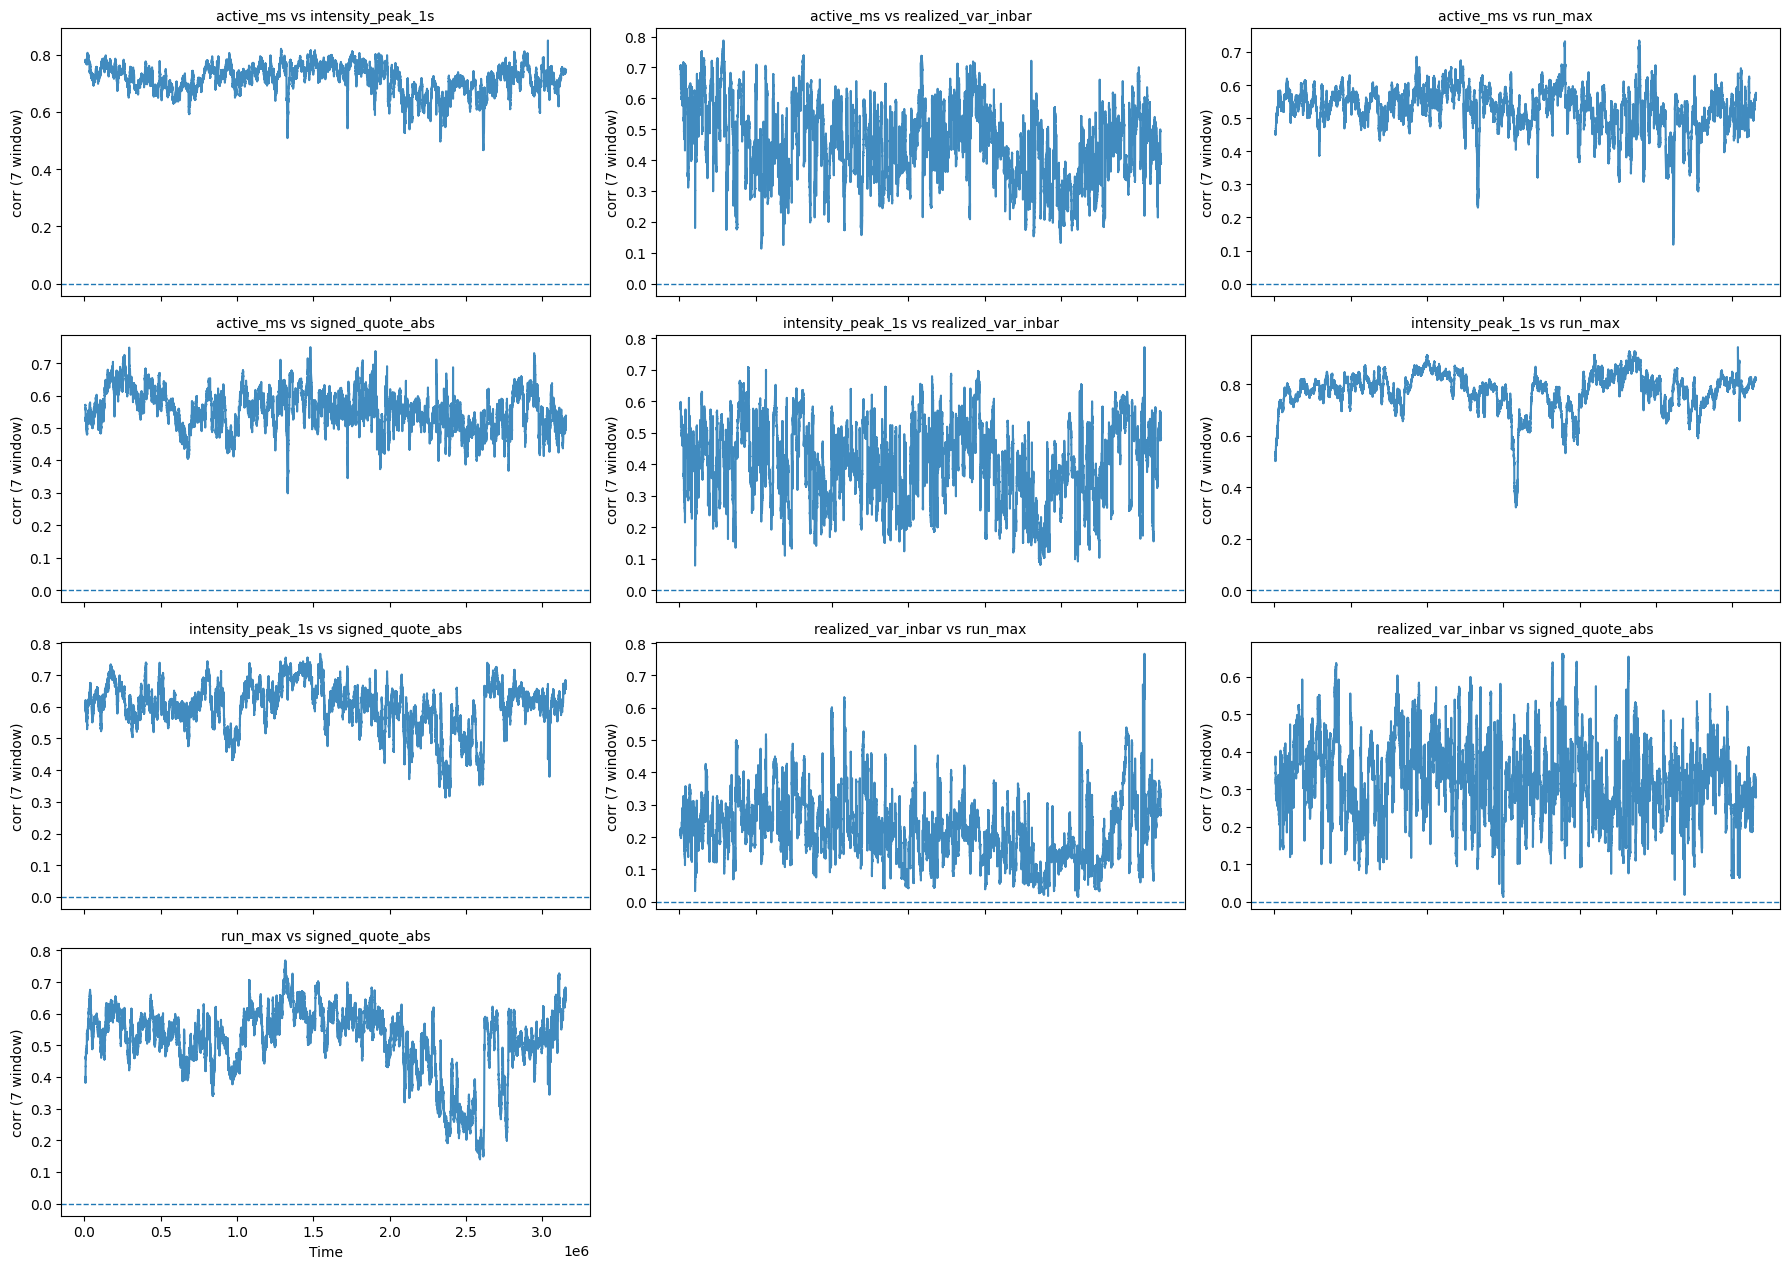

In [ ]:
import numpy as np

n = len(pairs)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(18, 3.2 * nrows),
    sharex=True
)

axes = np.array(axes).reshape(-1)

for idx, (a, b) in enumerate(pairs):
    ax = axes[idx]
    s = rc_mat[(a, b)]

    ax.plot(rc_mat.index, s, alpha=0.85)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"{a} vs {b}", fontsize=10)
    ax.set_ylabel(f"corr ({DAYS} window)")

# ปิดแกนที่เหลือถ้า subplot เกิน
for k in range(n, len(axes)):
    axes[k].axis("off")

axes[min(n-1, len(axes)-1)].set_xlabel("Time")
plt.tight_layout()
plt.show()

## EDA Note

---

### วิเคราะห์ Dist ทีละ Feature

---

### 1️⃣ `avg_trade_q`

**สิ่งที่เห็นจาก dist**

* unimodal
* right-skew
* ไม่มี spike รุนแรง
* scale drift ตามปี แต่ shape ใกล้กัน

**สรุปเชิงสถิติ**

* ❌ ไม่ใช่ event
* ❌ ไม่เหมาะ threshold แบบ hard
* ✅ ดีมากเป็น background liquidity condition

**บทบาทที่เหมาะ**

* ✅ **Core state**
* ✅ Behavior: slope / rolling mean
* ❌ Event

**เหตุผล**

> มันบอก “ใครกำลัง trade” มากกว่า “เกิดอะไรขึ้น”

---

### 2️⃣ `active_ms`

**สิ่งที่เห็น**

* heavy tail
* long right tail
* scale drift ชัด
* มี burst แต่ไม่เป็น spike แบบ impulse

**สรุป**

* อยู่กึ่งกลางระหว่าง state กับ stress
* event เดี่ยว ๆ ไม่ชัด
* interaction สำคัญ

**บทบาท**

* ✅ **Core state**
* ✅ Behavior (delta, slope)
* ⚠️ Event (เฉพาะ extreme)

**เหตุผล**

> active_ms = crowd density / temporal compression

---

### 3️⃣ `realized_var_inbar`

**สิ่งที่เห็น**

* extremely skewed
* mass ใกล้ 0
* tail แรงมาก
* shape stable

**สรุป**

* classic impulse metric
* state ใช้ไม่ได้

**บทบาท**

* ❌ Core state
* ✅ **Event**
* ⚠️ Behavior (rolling mean ได้เล็กน้อย)

**เหตุผล**

> volatility “เกิดเป็น episode” ไม่ใช่ climate

---

### 4️⃣ `flip_count`

**สิ่งที่เห็น**

* discrete
* heavy tail
* scale drift
* structure ชัด

**สรุป**

* raw value ใช้ยาก
* rate สำคัญกว่า count

**บทบาท**

* ❌ Core state
* ⚠️ Event (burst of disagreement)
* ✅ **Behavior (convert → flip_rate)**

---

### 5️⃣ `flip_rate`

**สิ่งที่เห็น**

* unimodal
* bounded
* shape stable มาก
* center meaningful

**สรุป**

* หนึ่งใน feature ที่ “สะอาด” ที่สุด

**บทบาท**

* ✅ **Core state**
* ✅ Behavior (slope)
* ❌ Event

**เหตุผล**

> flip_rate = disagreement regime

---

### 6️⃣ `run_mean`

**สิ่งที่เห็น**

* bell-like
* shape stable
* scale drift ตาม regime
* center informative

**สรุป**

* persistence indicator แท้

**บทบาท**

* ✅ **Core state**
* ✅ Behavior (delta, slope)
* ❌ Event

---

### 7️⃣ `run_max`

**สิ่งที่เห็น**

* heavy tail
* skewed
* event-like spikes
* distribution ไม่ symmetric

**สรุป**

* ไม่เหมาะเป็น state
* ใช้จับ dominance episode

**บทบาท**

* ❌ Core state
* ✅ **Event**
* ⚠️ Behavior (rolling max / freq)

---

### 8️⃣ `intensity_peak_1s`

**สิ่งที่เห็น**

* spike ชัด
* long tail
* episodic
* shape stable

**สรุป**

* pure impulse metric

**บทบาท**

* ❌ Core state
* ✅ **Event**
* ❌ Behavior (นอกจาก count / frac)

---

### 9️⃣ `signed_quote` (p05–p95)

**สิ่งที่เห็น**

* symmetric
* peaked
* shape invariant
* tail ยัง meaningful

**สรุป**

* ตัวเดียวที่ทำได้ “สองบทบาท”

**บทบาท**

* ✅ **Core state (core band)**
* ✅ **Event (tail)**
* ✅ Behavior (slope, persistence)

---

### สรุปในตารางเดียว (decision-ready)

| Feature            | Core State | Event | Behavior |
| ------------------ | ---------- | ----- | -------- |
| avg_trade_q        | ✅          | ❌     | ✅        |
| active_ms          | ✅          | ⚠️    | ✅        |
| realized_var_inbar | ❌          | ✅     | ⚠️       |
| flip_count         | ❌          | ⚠️    | ❌        |
| flip_rate          | ✅          | ❌     | ✅        |
| run_mean           | ✅          | ❌     | ✅        |
| run_max            | ❌          | ✅     | ⚠️       |
| intensity_peak_1s  | ❌          | ✅     | ❌        |
| signed_quote       | ✅          | ✅     | ✅        |

---

### Canonical decomposition (clean & minimal)

**Core State vector**

```
S_t = (
  avg_trade_q,
  active_ms,
  flip_rate,
  run_mean,
  signed_quote_core
)
```

**Event vector**

```
E_t = (
  realized_var_inbar,
  intensity_peak_1s,
  run_max,
  signed_quote_tail
)
```

**Behavior / Drift**

```
B_t = (
  slope(avg_trade_q),
  slope(active_ms),
  slope(flip_rate),
  slope(run_mean),
  slope(signed_quote)
)
```

# Adaptive L

## Function

In [ ]:
import polars as pl
import numpy as np
from math import exp
from dataclasses import dataclass, asdict

# =========================
# CONFIG (ใช้ร่วมกันทุก feature)
# =========================

@dataclass
class AdaptiveWindowConfig:
    # --- L bounds ---
    Lmin: float = 120.0
    Lmax: float = 480.0

    # --- drift score ---
    C_days: int = 28
    QGRID: tuple = tuple(i / 100 for i in range(5, 100, 5))
    EPS: float = 1e-12

    # --- smoothing ---
    alpha_D: float = 0.35
    alpha_E: float = 0.30

    # --- tail calibration ---
    H_days_default: int = 56
    H_days_slow: int = 84
    deadband_95: float = 0.012
    deadband_99: float = 0.004
    min_exp_exceed_99: int = 30

    # --- adaptive baseline / gating ---
    warmup_weeks: int = 26
    baseline_weeks: int = 52
    D_gate_margin: float = 0.15

    # --- calibration scaling ---
    E_star: float = 0.01
    scale_cap: float = 0.6

    # --- weekly rate limiter ---
    min_factor: float = 0.88
    max_factor: float = 1.12

    # --- mean reversion anchor ---
    L_anchor: float = 220.0
    lam: float = 0.06

    # --- barrier function internal default (ถ้าอยากให้ต่างจาก Lmin/Lmax ก็แก้ได้) ---
    barrier_Lmin: float | None = None
    barrier_Lmax: float | None = None

    disable_calibration_when_drift_high: bool = False

    kD_lengthen_mult: float = 0.6
    edge_push_strength: float = 0.12
    edge_zone: float = 0.10

    baseQuantile: float = 0.5

    min_obs_drift: int = 5000


CFG = AdaptiveWindowConfig()


# =========================
# HELPERS
# =========================

def clip(x, lo, hi):
    return max(lo, min(hi, x))

def quantiles(df: pl.DataFrame, col: str, qs, *, eps=np.nan) -> np.ndarray:
    s = df.select(col).drop_nulls()
    if s.height == 0:
        return np.array([eps] * len(qs), dtype=float)

    out = []
    for q in qs:
        v = s.select(pl.col(col).quantile(q)).item()
        out.append(float(v) if v is not None else np.nan)
    return np.array(out, dtype=float)

def drift_score_quantile_w1(df: pl.DataFrame, col: str, t: pl.Datetime, *, cfg: AdaptiveWindowConfig) -> float:
    recent = df.filter((pl.col("t") >= t - pl.duration(days=cfg.C_days)) & (pl.col("t") < t))
    prev   = df.filter((pl.col("t") >= t - pl.duration(days=2 * cfg.C_days)) & (pl.col("t") < t - pl.duration(days=cfg.C_days)))

    if recent.height == 0 or prev.height == 0:
        return 0.0

    Qr = quantiles(recent, col, cfg.QGRID, eps=np.nan)
    Qp = quantiles(prev,   col, cfg.QGRID, eps=np.nan)

    W = float(np.nanmean(np.abs(Qr - Qp)))

    q25, q75 = quantiles(prev, col, [0.25, 0.75], eps=np.nan)
    iqr = float(q75 - q25)

    return W / max(iqr, cfg.EPS)

def barrier_weights(L, *, cfg: AdaptiveWindowConfig):
    Lmin = cfg.barrier_Lmin if cfg.barrier_Lmin is not None else cfg.Lmin
    Lmax = cfg.barrier_Lmax if cfg.barrier_Lmax is not None else cfg.Lmax
    z = (L - Lmin) / (Lmax - Lmin)
    z = max(0.0, min(1.0, z))
    w_shorten  = 0.2 + 0.8 * z
    w_lengthen = 0.2 + 0.8 * (1.0 - z)
    return w_shorten, w_lengthen

def tail_calibration_multiweek(
    df: pl.DataFrame,
    col: str,
    t,
    L_days: float,
    *,
    cfg: AdaptiveWindowConfig,
    H_days: int | None = None,
):
    L_int = int(round(L_days))
    H = int(H_days if H_days is not None else cfg.H_days_default)

    train = (
        df.filter((pl.col("t") >= t - pl.duration(days=L_int)) & (pl.col("t") < t))
          .select(["t", col])
          .drop_nulls(subset=[col])
    )
    hold = (
        df.filter((pl.col("t") >= t) & (pl.col("t") < t + pl.duration(days=H)))
          .select(["t", col])
          .drop_nulls(subset=[col])
    )
    if train.height == 0 or hold.height == 0:
        return None

    T95 = train.select(pl.col(col).quantile(0.95)).item()
    T99 = train.select(pl.col(col).quantile(0.99)).item()
    if T95 is None or T99 is None:
        return None

    n = hold.height
    p95_val = hold.select((pl.col(col) > pl.lit(T95)).mean()).item()
    p99_val = hold.select((pl.col(col) > pl.lit(T99)).mean()).item()
    if p95_val is None or p99_val is None:
        return None

    p95 = float(p95_val)
    p99 = float(p99_val)

    e95 = p95 - 0.05
    e99 = p99 - 0.01

    e95_eff = 0.0 if abs(e95) <= cfg.deadband_95 else e95

    exp99 = 0.01 * n
    used_99 = exp99 >= cfg.min_exp_exceed_99
    if (not used_99) or (abs(e99) <= cfg.deadband_99):
        e99_eff = 0.0
    else:
        e99_eff = e99

    E = 0.5 * abs(e95_eff) + 1.0 * abs(e99_eff)

    def sgn(x: float) -> float:
        return 1.0 if x > 0 else (-1.0 if x < 0 else 0.0)

    S = 0.5 * sgn(e95_eff) + 1.0 * sgn(e99_eff)

    return {
        "n_hold": n,
        "p95": p95,
        "p99": p99,
        "e95": e95,
        "e99": e99,
        "e95_eff": e95_eff,
        "e99_eff": e99_eff,
        "E": float(E),
        "S": float(S),
        "used_99": bool(used_99),
        "H_days": int(H),
    }

def update_L(
    L: float,
    Dbar: float,
    D_star: float,
    kD: float,
    Ebar: float,
    S: float,
    kE: float,
    *,
    cfg: AdaptiveWindowConfig,
    D_gate: float | None = None,
) -> float:
    """
    Stable adaptive window update with:
      1) Asymmetric drift (shorten faster, lengthen slower)
      2) Tail calibration (gated + capped)
      3) Mean reversion toward anchor
      4) Soft repulsion near bounds (prevents sticking to Lmin/Lmax)
      5) Weekly rate limiter
    """
    Lmin, Lmax = cfg.Lmin, cfg.Lmax
    L = float(L)

    w_shorten, w_lengthen = barrier_weights(L, cfg=cfg)

    # -------------------------
    # 1) DRIFT UPDATE (asymmetric)
    # -------------------------
    delta = float(Dbar - D_star)  # >0 shorten, <0 lengthen

    # lengthen should be slower than shorten (prevents drifting to Lmax)
    kD_lengthen_mult = cfg.kD_lengthen_mult
    if delta > 0:
        kD_eff = kD * w_shorten
    else:
        kD_eff = kD * kD_lengthen_mult * w_lengthen

    if delta < 0 and L > 0.75 * Lmax:
      kD_eff *= 0.6

    Ld = clip(L * exp(-kD_eff * delta), Lmin, Lmax)

    # -------------------------
    # 2) CALIBRATION UPDATE (gated + capped)
    # -------------------------
    S_eff = float(S)
    if D_gate is not None and Dbar > D_gate:
        if getattr(cfg, "disable_calibration_when_drift_high", False):
            S_eff = 0.0
        else:
            S_eff = max(S_eff, 0.0)

    scale = min(Ebar / max(cfg.E_star, cfg.EPS), cfg.scale_cap)

    # If no calibration signal, skip exp to avoid tiny numerical nudges
    if S_eff == 0.0 or scale == 0.0:
        Lc = Ld
    else:
        kE_eff = kE * (w_shorten if S_eff > 0 else w_lengthen)
        Lc = clip(Ld * exp(-kE_eff * S_eff * scale), Lmin, Lmax)

    # -------------------------
    # 3) MEAN REVERSION (log-space) toward anchor
    # -------------------------
    Lc_safe = max(Lc, cfg.EPS)
    Lmr = Lc * exp(cfg.lam * (np.log(cfg.L_anchor) - np.log(Lc_safe)))
    Lmr = clip(Lmr, Lmin, Lmax)

    # -------------------------
    # 4) SOFT REPULSION NEAR BOUNDS
    # -------------------------
    # edge_zone: fraction of range considered "near the wall"
    edge_zone = cfg.edge_zone            # 10% of range on each side
    edge_push_strength = cfg.edge_push_strength   # small; prevents sticking without overreacting

    rng = max(Lmax - Lmin, cfg.EPS)
    hi0 = Lmax - edge_zone * rng
    lo0 = Lmin + edge_zone * rng

    push = 0.0
    if Lmr > hi0:
        # push negative when too close to upper bound
        push = -edge_push_strength * ((Lmr - hi0) / max(rng, cfg.EPS))
    elif Lmr < lo0:
        # push positive when too close to lower bound
        push = +edge_push_strength * ((lo0 - Lmr) / max(rng, cfg.EPS))

    if push != 0.0:
        Lmr = clip(Lmr * exp(push), Lmin, Lmax)

    # -------------------------
    # 5) WEEKLY RATE LIMITER (final)
    # -------------------------
    factor = Lmr / max(L, cfg.EPS)
    factor = max(cfg.min_factor, min(cfg.max_factor, factor))
    return clip(L * factor, Lmin, Lmax)

def monday_anchors(df: pl.DataFrame) -> list:
    return (
        df.select(pl.col("t").dt.truncate("1w").alias("w"))
          .unique()
          .sort("w")
          .get_column("w")
          .to_list()
    )

def run_adaptive_window(
    df: pl.DataFrame,
    col: str,
    *,
    L0: float,
    D_star0: float,
    kD: float,
    kE: float,
    cfg: AdaptiveWindowConfig = CFG,
    H_days: int | None = None,   # ถ้าไม่ส่งมา จะใช้ cfg.H_days_default
):
    anchors = monday_anchors(df)

    L = float(L0)
    Dbar = 0.0
    Ebar = 0.0
    D_hist = []

    records = []

    for i, t in enumerate(anchors):
        D = drift_score_quantile_w1(df, col, t, cfg=cfg)
        Dbar = cfg.alpha_D * D + (1 - cfg.alpha_D) * Dbar
        D_hist.append(D)

        # adaptive baseline
        if i >= cfg.warmup_weeks:
            base = np.array(D_hist[-cfg.baseline_weeks:], dtype=float)
            D_star_eff = float(np.quantile(base, cfg.baseQuantile))  # << เปลี่ยนจาก median
        else:
            D_star_eff = float(D_star0)

        D_gate = D_star_eff + cfg.D_gate_margin

        cal = tail_calibration_multiweek(
            df, col, t, L_days=L, cfg=cfg, H_days=H_days
        )

        E = 0.0
        S = 0.0
        if cal is not None:
            E = cal["E"]
            S = cal["S"]
            Ebar = cfg.alpha_E * E + (1 - cfg.alpha_E) * Ebar
        else:
            Ebar = (1 - cfg.alpha_E) * Ebar

        L_new = update_L(
            L, Dbar, D_star_eff, kD, Ebar, S, kE,
            cfg=cfg, D_gate=D_gate
        )

        records.append({
            "t": t,
            "L": L,
            "L_new": L_new,
            "D": D,
            "Dbar": Dbar,
            "D_star_eff": D_star_eff,
            "D_gate": D_gate,
            "E": E,
            "Ebar": Ebar,
            "S": S,
            "H_days": (cal["H_days"] if cal is not None else (H_days if H_days is not None else cfg.H_days_default)),
        })

        L = L_new

    return pl.DataFrame(records)

In [ ]:
import matplotlib.pyplot as plt
import polars as pl

def _to_dt_expr(x, unit="us"):
    if x is None:
        return None
    if isinstance(x, str):
        return pl.lit(x).str.strptime(pl.Datetime(unit), strict=False)
    return pl.lit(x).cast(pl.Datetime(unit), strict=False)

def plot_adaptive_dashboard(
    df_merged: pl.DataFrame,     # ต้องมี: t, L, <feature_col>
    feature_col: str,            # เช่น "V_log_mean_240m"
    *,
    start=None,
    end=None,
    unit="us",
    title=None,
):
    dff = df_merged

    # --- filter time range ---
    if start is not None:
        dff = dff.filter(pl.col("t") >= _to_dt_expr(start, unit=unit))
    if end is not None:
        dff = dff.filter(pl.col("t") <= _to_dt_expr(end, unit=unit))

    # --- columns needed ---
    need = ["t", "L", feature_col, "Dbar", "D_star_eff", "D_gate", "Ebar", "S"]
    have = [c for c in need if c in dff.columns]

    pdf = dff.select(have).to_pandas()

    fig, axes = plt.subplots(
        4, 1,
        figsize=(13, 11),
        sharex=True,
        gridspec_kw={"height_ratios": [1.4, 1.0, 1.1, 1.0]}
    )

    ax1, ax2, ax3, ax4 = axes

    # ----------------------
    # Pane 1: L
    # ----------------------
    ax1.plot(pdf["t"], pdf["L"], linewidth=2, label="L")
    ax1.set_ylabel("L (days)")
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="upper left")

    # ----------------------
    # Pane 2: Feature
    # ----------------------
    if feature_col in pdf.columns:
        ax2.plot(pdf["t"], pdf[feature_col], linestyle="--", linewidth=1.8, label=feature_col)
        ax2.set_ylabel(feature_col)
        ax2.grid(True, alpha=0.3)
        ax2.legend(loc="upper left")
    else:
        ax2.text(0.01, 0.5, f"Missing column: {feature_col}", transform=ax2.transAxes)
        ax2.grid(True, alpha=0.3)

    # ----------------------
    # Pane 3: Drift
    # ----------------------
    if "Dbar" in pdf.columns:
        ax3.plot(pdf["t"], pdf["Dbar"], linewidth=2, label="Dbar")
    if "D_star_eff" in pdf.columns:
        ax3.plot(pdf["t"], pdf["D_star_eff"], linestyle="--", linewidth=1.8, label="D_star_eff")
    if "D_gate" in pdf.columns:
        ax3.plot(pdf["t"], pdf["D_gate"], linestyle=":", linewidth=1.5, label="D_gate")

    ax3.set_ylabel("Drift")
    ax3.grid(True, alpha=0.3)
    ax3.legend(loc="upper left")

    # ----------------------
    # Pane 4: Calibration
    # ----------------------
    if "Ebar" in pdf.columns:
        ax4.plot(pdf["t"], pdf["Ebar"], linewidth=2, label="Ebar")
    if "S" in pdf.columns:
        ax4.plot(pdf["t"], pdf["S"], linestyle="--", linewidth=1.8, label="S")
    ax4.axhline(0.0, linewidth=1.0)

    ax4.set_ylabel("Calib")
    ax4.set_xlabel("Time")
    ax4.grid(True, alpha=0.3)
    ax4.legend(loc="upper left")

    # ----------------------
    # Title
    # ----------------------
    if title is None:
        title = f"Adaptive Window Dashboard ({feature_col})"
    fig.suptitle(title, y=0.99)

    plt.tight_layout()
    plt.show()

In [ ]:
import polars as pl

def run_constant_window(
    df: pl.DataFrame,
    col: str,
    *,
    L_const: float,
    cfg: AdaptiveWindowConfig = CFG,
    H_days: int | None = None,
    fill_stats: str = "zero",  # "zero" | "null"
) -> pl.DataFrame:
    """
    Constant-L version of run_adaptive_window.
    Returns weekly anchor records with the same schema style:
      t, L, L_new, D, Dbar, D_star_eff, D_gate, E, Ebar, S, H_days

    Notes:
    - L == L_new == L_const for every anchor.
    - drift / calibration stats are filled with zeros or nulls.
    """
    anchors = monday_anchors(df)

    H = int(H_days if H_days is not None else cfg.H_days_default)
    Lc = float(L_const)

    if fill_stats == "null":
        D = Dbar = D_star_eff = D_gate = E = Ebar = S = None
    else:
        D = Dbar = D_star_eff = D_gate = E = Ebar = S = 0.0

    records = []
    for t in anchors:
        records.append({
            "t": t,
            "L": Lc,
            "L_new": Lc,
            "D": D,
            "Dbar": Dbar,
            "D_star_eff": D_star_eff,
            "D_gate": D_gate,
            "E": E,
            "Ebar": Ebar,
            "S": S,
            "H_days": H,
        })

    return pl.DataFrame(records)

## active ms

In [ ]:
# cfg_A = AdaptiveWindowConfig(
#     Lmin=180.0, Lmax=390.0,

#     alpha_D=0.28,
#     alpha_E=0.30,

#     E_star=0.012,
#     scale_cap=0.55,

#     min_factor=0.92,
#     max_factor=1.08,

#     L_anchor=300.0,
#     lam=0.050,

#     D_gate_margin=0.15,
#     disable_calibration_when_drift_high=True,

#     kD_lengthen_mult=0.50,
#     edge_push_strength=0.05,
#     edge_zone=0.15,

#     baseQuantile=0.50
# )

# res_A = run_adaptive_window(
#     df_Feature,
#     "active_ms",
#     L0=300.0,
#     D_star0=0.43,
#     kD=0.30,
#     kE=0.18,
#     cfg=cfg_A,
#     H_days=84,
# )

In [ ]:
# resA_merged = (
#     res_A
#     .join(
#         df.with_columns(pl.col("t").cast(pl.Datetime("us")))
#           .select(["t", "active_ms"]),
#         on="t",
#         how="left"
#     )
# )

# plot_adaptive_dashboard(resA_merged, "active_ms", start="2020-01-01", end="2025-12-31")

In [ ]:
res_A_climate_const = run_constant_window(
    df_Feature,
    "active_ms",
    L_const=120.0,
    fill_stats="zero",
)

In [ ]:
res_A_event_const = run_constant_window(
    df_Feature,
    "active_ms",
    L_const=30.0,
    fill_stats="zero",
)

## flip_rate

In [ ]:
res_f_climate_const = run_constant_window(
    df_Feature,
    "flip_rate",
    L_const=120.0,
    fill_stats="zero",
)

## avg_trade_q

In [ ]:
res_atq_climate_const = run_constant_window(
    df_Feature,
    "avg_trade_q",
    L_const=120.0,
    fill_stats="zero",
)

In [ ]:
res_atq_event_const = run_constant_window(
    df_Feature,
    "avg_trade_q",
    L_const=30.0,
    fill_stats="zero",
)

## run_mean

In [ ]:
res_runmean_climate_const = run_constant_window(
    df_Feature,
    "run_mean",
    L_const=120.0,
    fill_stats="zero",
)

## signed_quote

In [ ]:
res_sq_climate_const = run_constant_window(
    df_Feature,
    "signed_quote",
    L_const=180.0,
    fill_stats="zero",
)

In [ ]:
res_sq_event_const = run_constant_window(
    df_Feature,
    "signed_quote",
    L_const=30.0,
    fill_stats="zero",
)

## rv_sqrt

In [ ]:
res_rs_climate_const = run_constant_window(
    df_Feature,
    "rv_sqrt",
    L_const=120.0,
    fill_stats="zero",
)

In [ ]:
res_rs_event_const = run_constant_window(
    df_Feature,
    "rv_sqrt",
    L_const=60.0,
    fill_stats="zero",
)

## run_max

In [ ]:
res_runmax_event_const = run_constant_window(
    df_Feature,
    "run_max",
    L_const=60.0,
    fill_stats="zero",
)

## intensity_peak_1s

In [ ]:
res_ip1_event_const = run_constant_window(
    df_Feature,
    "intensity_peak_1s",
    L_const=60.0,
    fill_stats="zero",
)

# Add Feature

## Function

### Add ECDF (Like) by Adaptive L

In [ ]:
import polars as pl
import math

def summarize_L(res_L: pl.DataFrame, col_prefer="L_new") -> pl.DataFrame:
    c = col_prefer if col_prefer in res_L.columns else "L"
    return res_L.select([
        pl.col(c).min().alias("L_min"),
        pl.col(c).quantile(0.05).alias("L_p05"),
        pl.col(c).quantile(0.25).alias("L_p25"),
        pl.col(c).median().alias("L_p50"),
        pl.col(c).quantile(0.75).alias("L_p75"),
        pl.col(c).quantile(0.95).alias("L_p95"),
        pl.col(c).max().alias("L_max"),
    ])

def build_L_grid_from_res(
    res_L: pl.DataFrame,
    *,
    step_days: int = 30,
    pad_days: int = 0,
    snap: int = 10,
    col_prefer="L_new",
) -> list[int]:
    """
    Grid spanning [min,max] (or p05..p95 if you want) with fixed step.
    snap: round endpoints to nearest snap days (e.g. 10)
    """
    c = col_prefer if col_prefer in res_L.columns else "L"
    s = res_L.select(pl.col(c).drop_nulls())
    mn = float(s.min().item())
    mx = float(s.max().item())

    mn -= pad_days
    mx += pad_days

    # snap endpoints
    mn = math.floor(mn / snap) * snap
    mx = math.ceil(mx / snap) * snap

    grid = list(range(int(mn), int(mx) + 1, int(step_days)))
    if grid[-1] != int(mx):
        grid.append(int(mx))
    return sorted(set(grid))

In [ ]:
# print(summarize_L(res_A_const))
# L_grid = build_L_grid_from_res(res_A_const, step_days=30, pad_days=0, snap=10)
# L_grid

In [ ]:
import polars as pl

def _const_L_period_from_res(res_L: pl.DataFrame) -> str:
    c = "L_new" if "L_new" in res_L.columns else "L"
    # ต้องเป็น constant จริง ๆ
    mn, mx = res_L.select([
        pl.col(c).drop_nulls().min(),
        pl.col(c).drop_nulls().max(),
    ]).row(0)
    if float(mx) != float(mn):
        raise ValueError(f"res_L is not constant: min={mn}, max={mx}")
    L_int = int(round(float(mn)))
    return f"{L_int}d"

def add_ms_quantiles_dfrolling_downsample(
    df: pl.DataFrame,
    *,
    res_L: pl.DataFrame | None = None,
    tcol="t",
    xcol="active_ms",
    L="120d",
    every="5m",
    how_5m="median",
    qs=(0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99),
    suffix="_L",
    min_samples=10000,
    log1p=False,
    prefix=None,
    suffix_with_L=True,
):
    df1 = df.sort(tcol)

    if res_L is not None:
        L = _const_L_period_from_res(res_L)

    # --- prefix ---
    if prefix is None:
        prefix = xcol  # default: ใช้ชื่อ feature ไปเลย

    # --- value expr + suffix ---
    if log1p:
        x = pl.col(xcol).cast(pl.Float64).log1p()
        suffix2 = "_logL"
    else:
        x = pl.col(xcol).cast(pl.Float64)
        suffix2 = suffix

    # --- append L into suffix (avoid collisions across grid) ---
    if suffix_with_L and isinstance(L, str):
        suffix2 = f"{suffix2}_{L}"

    agg_ds = {
        "mean": x.mean(),
        "median": x.median(),
        "last": x.last(),
        "max": x.max(),
        "p90": x.quantile(0.90),
    }[how_5m]

    # 1) downsample
    df_ds = (
        df1
        .select([tcol, xcol])
        .group_by_dynamic(tcol, every=every, period=every)
        .agg(agg_ds.alias(xcol))
        .sort(tcol)
    )

    # 2) rolling quantiles + count
    qcols = [f"{prefix}_q{int(round(q*1000)):04d}{suffix2}" for q in qs]
    agg_exprs = [pl.col(xcol).quantile(q).alias(name) for q, name in zip(qs, qcols)]
    cnt_col = f"{prefix}_cnt{suffix2}"

    roll_raw = (
        df_ds
        .rolling(index_column=tcol, period=L)
        .agg(agg_exprs + [pl.col(xcol).count().alias(cnt_col)])
        .sort(tcol)
    )

    # 3) mask by min_samples
    roll = (
        roll_raw
        .with_columns([
            pl.when(pl.col(cnt_col) >= min_samples)
              .then(pl.col(c))
              .otherwise(None)
              .alias(c)
            for c in qcols
        ])
        .drop(cnt_col)
    )

    # 4) join back
    out = df1.join_asof(roll, on=tcol, strategy="backward")
    return out, qcols

def piecewise_ecdf_like_safe(
    x: pl.Expr,
    qcols: list[str],
    qs: list[float],
    out="act_clim_ecdf_like_L",
    eps=1e-12,
):
    out_expr = (
        pl.when(x <= pl.col(qcols[0])).then(pl.lit(qs[0]))
        .when(x >= pl.col(qcols[-1])).then(pl.lit(qs[-1]))
    )

    for i in range(len(qs) - 1):
        ql, qh = qs[i], qs[i + 1]
        xl, xh = pl.col(qcols[i]), pl.col(qcols[i + 1])

        # only interpolate when xh > xl (avoid divide by 0 / flat knots)
        denom = (xh - xl)
        y = pl.lit(ql) + (x - xl) / denom.clip(lower_bound=eps) * (qh - ql)

        out_expr = out_expr.when((x > xl) & (x < xh) & (denom > 0)).then(y)

    return out_expr.otherwise(None).clip(0, 1).alias(out)

In [ ]:
def add_ms_quantiles_for_Lgrid(
    df: pl.DataFrame,
    *,
    tcol="t",
    xcol="active_ms",
    every="5m",
    how_5m="median",
    qs=(0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99),
    min_samples=10000,
    log1p=False,
    L_grid_days=(180,240,300,360),
):
    out = df.sort(tcol)
    qcols_by_L = {}

    for Ld in L_grid_days:
        L_str = f"{int(Ld)}d"

        out, qcols = add_ms_quantiles_dfrolling_downsample(
            out,
            res_L=None,
            tcol=tcol,
            xcol=xcol,
            L=L_str,
            every=every,
            how_5m=how_5m,
            qs=qs,
            min_samples=min_samples,
            log1p=log1p,
            suffix_with_L=True,   # <- จะได้ชื่อคอลัมน์มี 0300d
        )
        qcols_by_L[int(Ld)] = qcols

    return out, qcols_by_L

In [ ]:
def attach_Lt_from_res(
    df_bars: pl.DataFrame,
    res_L: pl.DataFrame,
    *,
    tcol="t",
    out_col="L_t",
    time_unit: str = "ms",   # "ms" or "us"
):
    c = "L_new" if "L_new" in res_L.columns else "L"

    # cast both sides to the same datetime unit
    t_left  = pl.col(tcol).cast(pl.Datetime(time_unit))
    t_right = pl.col("t").cast(pl.Datetime(time_unit))

    res = (
        res_L
        .select([
            t_right.alias("t_anchor"),
            pl.col(c).alias(out_col),
        ])
        .sort("t_anchor")
    )

    out = (
        df_bars
        .sort(tcol)
        .with_columns(t_left.alias(tcol))          # ensure left key unit
        .join_asof(res, left_on=tcol, right_on="t_anchor", strategy="backward")
        .drop("t_anchor")
    )
    return out

In [ ]:
def interpolate_quantiles_from_grid(
    df: pl.DataFrame,
    *,
    L_grid_days: list[int],
    qcols_by_L: dict[int, list[str]],
    qs=(0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99),
    L_t_col="L_t",
    out_prefix="act_q",
    out_suffix="_Lint",
):
    grid = sorted([int(x) for x in L_grid_days])
    if len(grid) == 0:
        raise ValueError("L_grid_days is empty")

    # output columns one per quantile
    out_cols = [f"{out_prefix}{int(round(q*1000)):04d}{out_suffix}" for q in qs]

    # -----------------------
    # CASE 1) constant grid
    # -----------------------
    if len(grid) == 1:
        L0 = grid[0]
        src_cols = qcols_by_L[L0]
        if len(src_cols) != len(out_cols):
            raise ValueError("qcols_by_L[L0] length does not match qs")

        return (
            df.with_columns([pl.col(src).alias(dst) for src, dst in zip(src_cols, out_cols)]),
            out_cols,
        )

    # -----------------------
    # CASE 2) true interpolation
    # -----------------------
    exprs = []
    for j, outc in enumerate(out_cols):
        e = None

        for k in range(len(grid) - 1):
            L0, L1 = grid[k], grid[k + 1]
            q0 = pl.col(qcols_by_L[L0][j])
            q1 = pl.col(qcols_by_L[L1][j])

            w = (pl.col(L_t_col) - pl.lit(float(L0))) / pl.lit(float(L1 - L0))
            w = w.clip(0, 1)
            interp = (pl.lit(1.0) - w) * q0 + w * q1

            cond = (pl.col(L_t_col) >= L0) & (pl.col(L_t_col) <= L1)
            if e is None:
                e = pl.when(cond).then(interp)
            else:
                e = e.when(cond).then(interp)

        # clamp outside grid to nearest endpoint
        e = (
            e.when(pl.col(L_t_col) < grid[0]).then(pl.col(qcols_by_L[grid[0]][j]))
             .when(pl.col(L_t_col) > grid[-1]).then(pl.col(qcols_by_L[grid[-1]][j]))
             .otherwise(None)
             .alias(outc)
        )
        exprs.append(e)

    return df.with_columns(exprs), out_cols

### Add EMA by Time

In [ ]:
def add_ema_by_time(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    xcol: str,
    span: int | None = None,      # เช่น 60 = EMA 60 bars
    alpha: float | None = None,   # เช่น 2/(span+1)
    adjust: bool = False,
    min_periods: int = 1,
    out: str | None = None,
    fill_null: str | None = "forward",  # None | "forward" | "zero"
) -> pl.DataFrame:
    """
    Add EMA column using Polars ewm_mean.
    - span or alpha must be provided.
    - Works well for 1m bars.
    """

    if (span is None) == (alpha is None):
        raise ValueError("Provide exactly one of span or alpha.")

    x = pl.col(xcol).cast(pl.Float64)

    if fill_null == "forward":
        x = x.forward_fill()
    elif fill_null == "zero":
        x = x.fill_null(0.0)
    elif fill_null is None:
        pass
    else:
        raise ValueError("fill_null must be None, 'forward', or 'zero'.")

    if out is None:
        out = f"{xcol}_ema_{span if span is not None else f'a{alpha:g}'}"

    ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)
    return df.with_columns([ema])

def add_ema_multi(
    df: pl.DataFrame,
    *,
    xcol: str,
    spans: list[int],
    prefix: str | None = None,
    **kwargs,
) -> pl.DataFrame:
    if prefix is None:
        prefix = xcol
    out = df
    for s in spans:
        out = add_ema_by_time(out, xcol=xcol, span=s, out=f"{prefix}_ema_{s}", **kwargs)
    return out

### Add Slope or Accel Slope by Time

In [ ]:
def add_slope(
    df: pl.DataFrame,
    *,
    xcol: str,
    ks: list[int] = [5, 15, 60],
    prefix: str | None = None,
) -> pl.DataFrame:
    if prefix is None:
        prefix = xcol

    x = pl.col(xcol).cast(pl.Float64)

    exprs = []
    for k in ks:
        # slope_k = (x_t - x_{t-k}) / k
        slope = ((x - x.shift(k)) / k).alias(f"{prefix}_slope_{k}")

        exprs += [slope]

    return df.with_columns(exprs)

In [ ]:
def add_accel(
    df: pl.DataFrame,
    *,
    xcol: str,
    ks: list[int] = [5, 15, 60],
    prefix: str | None = None,
) -> pl.DataFrame:
    if prefix is None:
        prefix = xcol

    x = pl.col(xcol).cast(pl.Float64)

    exprs = []
    for k in ks:
        # slope_k = (x_t - x_{t-k}) / k
        accel = ((x - 2 * x.shift(k) + x.shift(2 * k)) / k).alias(f"{prefix}_accel_{k}")

        exprs += [accel]

    return df.with_columns(exprs)

### Add Rolling (Quantile) Threshold by constant L

In [ ]:
import polars as pl
import math
from typing import Dict

def compute_thresholds_quantile(
    df: pl.DataFrame | pl.LazyFrame,
    specs: dict[str, dict[str, float]],
) -> dict[str, dict[str, float]]:
    lf = df.lazy() if isinstance(df, pl.DataFrame) else df

    agg_exprs = []
    names = []
    for col, flags in specs.items():
        for flag, p in flags.items():
            name = f"__thr__{col}__{flag}"
            names.append(name)
            agg_exprs.append(pl.col(col).quantile(p).alias(name))

    # collect once
    res = lf.select(agg_exprs).collect()
    row = res.row(0)
    flat = dict(zip(res.columns, row))

    out: Dict[str, Dict[str, float]] = {c: {} for c in specs.keys()}
    for k, v in flat.items():
        # "__thr__A_raw__xhi"
        parts = k.split("__")
        col = parts[2]
        flag = parts[3]
        out[col][flag] = float(v) if v is not None else float("nan")

    return out

In [ ]:
def build_L_grid_from_res(
    res_L: pl.DataFrame,
    *,
    step_days: int = 30,
    snap: int = 10,
    pad_days: int = 0,
    col_prefer: str = "L_new",
) -> list[int]:
    c = col_prefer if col_prefer in res_L.columns else "L"
    s = res_L.select(pl.col(c).drop_nulls())
    mn = float(s.min().item())
    mx = float(s.max().item())
    mn -= pad_days
    mx += pad_days

    mn = math.floor(mn / snap) * snap
    mx = math.ceil(mx / snap) * snap

    grid = list(range(int(mn), int(mx) + 1, int(step_days)))
    if len(grid) == 0:
        grid = [int(round((mn + mx) / 2))]
    if grid[-1] != int(mx):
        grid.append(int(mx))
    return sorted(set(grid))

In [ ]:
import math
import polars as pl

def _parse_every_to_seconds(every: str) -> int:
    # รองรับ "1m","5m","1h"
    if every.endswith("s"):
        return int(every[:-1])
    if every.endswith("m"):
        return int(every[:-1]) * 60
    if every.endswith("h"):
        return int(every[:-1]) * 3600
    if every.endswith("d"):
        return int(every[:-1]) * 86400
    raise ValueError(f"Unsupported every={every}")

def add_rolling_thresholds_quantile_Lgrid(
    df: pl.DataFrame,
    *,
    tcol="t",
    xcol="active_ms",
    every="5m",
    how="median",
    L_grid_days=(180,240,300,360),
    specs: dict[str, float] = None,
    min_samples: int | None = None,   # keep for backward compat
    min_frac: float | None = 0.2,     # NEW: fraction of window required (0..1]
    min_cap: int = 200,               # NEW: lower bound of min_samples
    prefix=None,
    log1p=False,
):
    if specs is None:
        specs = {"hi": 0.99}
    if prefix is None:
        prefix = xcol
    if min_frac is not None and not (0.0 < min_frac <= 1.0):
        raise ValueError("min_frac must be in (0,1]")

    df1 = df.sort(tcol)
    x = pl.col(xcol).cast(pl.Float64).log1p() if log1p else pl.col(xcol).cast(pl.Float64)

    agg_ds = {
        "mean": x.mean(),
        "median": x.median(),
        "last": x.last(),
        "max": x.max(),
        "p90": x.quantile(0.90),
    }[how]

    df_ds = (
        df1.select([tcol, xcol])
           .group_by_dynamic(tcol, every=every, period=every)
           .agg(agg_ds.alias(xcol))
           .sort(tcol)
    )

    thrcols_by_L: dict[int, list[str]] = {}
    out = df1

    every_sec = _parse_every_to_seconds(every)

    for Ld in sorted(set(int(x) for x in L_grid_days)):
        L = f"{Ld}d"

        # --- compute window size in #downsampled bars ---
        window_size = int((Ld * 86400) // every_sec)

        # resolve min_samples: prefer min_samples if user passed, else use min_frac
        if min_samples is not None:
            mo = int(min_samples)
        elif min_frac is not None:
            mo = max(min_cap, int(math.ceil(min_frac * window_size)))
        else:
            mo = 1  # no masking

        thrcols = []
        agg_exprs = []
        for flag, p in specs.items():
            name = f"{prefix}_thr_{flag}_L{Ld:04d}d"
            thrcols.append(name)
            agg_exprs.append(pl.col(xcol).quantile(p).alias(name))

        cnt_col = f"{prefix}_cnt_L{Ld:04d}d"

        roll_raw = (
            df_ds.rolling(index_column=tcol, period=L)
                 .agg(agg_exprs + [pl.col(xcol).count().alias(cnt_col)])
                 .sort(tcol)
        )

        roll = (
            roll_raw.with_columns([
                pl.when(pl.col(cnt_col) >= pl.lit(mo))
                  .then(pl.col(c))
                  .otherwise(None)
                  .alias(c)
                for c in thrcols
            ]).drop(cnt_col)
        )

        out = out.join_asof(roll, on=tcol, strategy="backward")
        thrcols_by_L[Ld] = thrcols

    return out, thrcols_by_L

In [ ]:
def interpolate_thresholds_from_grid(
    df: pl.DataFrame,
    *,
    L_grid_days: list[int],
    thrcols_by_L: dict[int, list[str]],
    flags: list[str],          # order must match specs order used above
    L_t_col="L_t",
    out_prefix="active_ms",
    out_suffix="_Lint",
):
    grid = sorted([int(x) for x in L_grid_days])
    if len(grid) == 0:
        raise ValueError("L_grid_days is empty")

    out_cols = [f"{out_prefix}_thr_{flag}{out_suffix}" for flag in flags]

    # constant L -> copy
    if len(grid) == 1:
        L0 = grid[0]
        src = thrcols_by_L[L0]
        return df.with_columns([pl.col(s).alias(d) for s, d in zip(src, out_cols)]), out_cols

    exprs = []
    for j, outc in enumerate(out_cols):
        e = None
        for k in range(len(grid) - 1):
            L0, L1 = grid[k], grid[k+1]
            y0 = pl.col(thrcols_by_L[L0][j])
            y1 = pl.col(thrcols_by_L[L1][j])

            w = (pl.col(L_t_col) - pl.lit(float(L0))) / pl.lit(float(L1 - L0))
            w = w.clip(0, 1)
            interp = (pl.lit(1.0) - w) * y0 + w * y1

            cond = (pl.col(L_t_col) >= L0) & (pl.col(L_t_col) <= L1)
            e = pl.when(cond).then(interp) if e is None else e.when(cond).then(interp)

        e = (
            e.when(pl.col(L_t_col) < grid[0]).then(pl.col(thrcols_by_L[grid[0]][j]))
             .when(pl.col(L_t_col) > grid[-1]).then(pl.col(thrcols_by_L[grid[-1]][j]))
             .otherwise(None)
             .alias(outc)
        )
        exprs.append(e)

    return df.with_columns(exprs), out_cols

### Add Event Flag

In [ ]:
import polars as pl

def add_event_flag_from_threshold(
    df: pl.DataFrame,
    *,
    xcol: str,                 # e.g. "active_ms"
    thr_hi: str | None = None, # e.g. "active_ms_thr_hi_Lint"
    thr_lo: str | None = None, # e.g. "active_ms_thr_lo_Lint"
    mode: str = "high",        # "high" | "low" | "two"
    out_flag: str | None = None,
    out_sev: str | None = None,
    sev_mode: str = "rank",    # "rank" | "ratio" | "logratio"
    eps: float = 1e-12,
) -> pl.DataFrame:
    """
    Create event flag (0/1) + optional severity from thresholds.
    - high: x > thr_hi
    - low:  x < thr_lo
    - two:  (x > thr_hi) or (x < thr_lo)

    Severity:
    - rank: map exceedance to (0..1) using distance from threshold normalized by abs(thr)
            (not a true rank, but monotone & scale-ish)
    - ratio: x / thr_hi (or thr_lo / x for low)
    - logratio: log(x/thr_hi) (or log(thr_lo/x) for low)
    """
    if out_flag is None:
        out_flag = f"{xcol}_evt"
    if out_sev is None and sev_mode is not None:
        out_sev = f"{xcol}_sev"

    x = pl.col(xcol).cast(pl.Float64)

    if mode == "high":
        if thr_hi is None:
            raise ValueError("thr_hi is required for mode='high'")
        th = pl.col(thr_hi).cast(pl.Float64)
        flag = (x > th)

        if sev_mode == "rank":
            sev = ((x - th) / (th.abs() + eps)).clip(0, 10)
        elif sev_mode == "ratio":
            sev = (x / (th + eps)).clip(0, 10)
        elif sev_mode == "logratio":
            sev = ((x + eps) / (th + eps)).log().clip(0, 10)
        else:
            sev = None

    elif mode == "low":
        if thr_lo is None:
            raise ValueError("thr_lo is required for mode='low'")
        th = pl.col(thr_lo).cast(pl.Float64)
        flag = (x < th)

        if sev_mode == "rank":
            sev = ((th - x) / (th.abs() + eps)).clip(0, 10)
        elif sev_mode == "ratio":
            sev = ((th + eps) / (x + eps)).clip(0, 10)
        elif sev_mode == "logratio":
            sev = ((th + eps) / (x + eps)).log().clip(0, 10)
        else:
            sev = None

    elif mode == "two":
        if thr_hi is None or thr_lo is None:
            raise ValueError("thr_hi and thr_lo are required for mode='two'")
        thi = pl.col(thr_hi).cast(pl.Float64)
        tlo = pl.col(thr_lo).cast(pl.Float64)

        flag_hi = (x > thi)
        flag_lo = (x < tlo)
        flag = flag_hi | flag_lo

        if sev_mode == "rank":
            sev_hi = ((x - thi) / (thi.abs() + eps)).clip(0, 10)
            sev_lo = ((tlo - x) / (tlo.abs() + eps)).clip(0, 10)
            sev = pl.when(flag_hi).then(sev_hi).when(flag_lo).then(sev_lo).otherwise(0.0)
        elif sev_mode == "ratio":
            sev_hi = (x / (thi + eps)).clip(0, 10)
            sev_lo = ((tlo + eps) / (x + eps)).clip(0, 10)
            sev = pl.when(flag_hi).then(sev_hi).when(flag_lo).then(sev_lo).otherwise(1.0)
        elif sev_mode == "logratio":
            sev_hi = ((x + eps) / (thi + eps)).log().clip(0, 10)
            sev_lo = ((tlo + eps) / (x + eps)).log().clip(0, 10)
            sev = pl.when(flag_hi).then(sev_hi).when(flag_lo).then(sev_lo).otherwise(0.0)
        else:
            sev = None
    else:
        raise ValueError("mode must be 'high', 'low', or 'two'")

    exprs = [flag.cast(pl.Int8).alias(out_flag)]
    if sev is not None and out_sev is not None:
        # severity only meaningful when flag=1; else 0
        exprs.append(pl.when(flag).then(sev).otherwise(0.0).alias(out_sev))

    return df.with_columns(exprs)

### Add Event Frac by Time

In [ ]:
import polars as pl
from typing import Union

MinObs = Union[None, int, float, dict[int, int]]

def add_flag_fracs(
    df: pl.DataFrame | pl.LazyFrame,
    *,
    flag_cols: list[str],
    windows_minutes: list[int] = [60, 240],
    bar_seconds: int = 60,
    min_obs: MinObs = None,        # None | int | float(frac) | dict[minutes -> int]
    prefix: str = "",
) -> pl.DataFrame | pl.LazyFrame:
    lf = df.lazy() if isinstance(df, pl.DataFrame) else df

    def resolve_min_obs(window_size: int, L_min: int) -> int:
        # default: require full window
        if min_obs is None:
            return int(window_size)

        # fixed integer
        if isinstance(min_obs, int):
            return int(min_obs)

        # fraction of window
        if isinstance(min_obs, float):
            if not (0.0 < min_obs <= 1.0):
                raise ValueError("min_obs as float must be in (0, 1]")
            return max(1, int((window_size * min_obs) + 0.999999))  # ceil

        # per-window dict
        if isinstance(min_obs, dict):
            if L_min not in min_obs:
                # if not provided, fall back to full window
                return int(window_size)
            return int(min_obs[L_min])

        raise TypeError("min_obs must be None, int, float, or dict[int,int]")

    exprs: list[pl.Expr] = []
    for L in windows_minutes:
        if L <= 0:
            raise ValueError("windows_minutes must be positive integers")

        # number of bars in L minutes
        window = max(1, int((L * 60 + bar_seconds - 1) // bar_seconds))
        mo = resolve_min_obs(window, int(L))

        for fcol in flag_cols:
            out_name = f"{prefix}{fcol}_frac_{L}m"

            num = (
                pl.col(fcol)
                .cast(pl.UInt8)
                .rolling_sum(window_size=window, min_periods=1)
            )

            den = (
                pl.col(fcol)
                .is_not_null()
                .cast(pl.UInt32)
                .rolling_sum(window_size=window, min_periods=1)
            )

            exprs.append(
                pl.when(den >= pl.lit(mo))
                .then(num / den)
                .otherwise(None)
                .alias(out_name)
            )

    out = lf.with_columns(exprs)
    return out.collect() if isinstance(df, pl.DataFrame) else out

## active_ms

In [ ]:
qs = (0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99)

# 1) เลือก L grid จาก res_A
L_grid = build_L_grid_from_res(res_A_climate_const, step_days=30, snap=10)

In [ ]:
# 2) คำนวณ quantiles สำหรับทุก L ใน grid
df_q, qcols_by_L = add_ms_quantiles_for_Lgrid(
    df_Feature,
    xcol="active_ms",
    every="5m",
    how_5m="median",
    qs=qs,
    min_samples=10000,
    log1p=False,
    L_grid_days=L_grid,
)

In [ ]:
# 3) attach L(t) จาก res_A
df_q = attach_Lt_from_res(df_q, res_A_climate_const, out_col="L_t", time_unit="ms")

In [ ]:
# 4) interpolate quantiles → ได้ชุด q ที่ “adaptive-like”
df_q, qcols_int = interpolate_quantiles_from_grid(
    df_q,
    L_grid_days=L_grid,
    qcols_by_L=qcols_by_L,
    qs=qs,
    L_t_col="L_t",
    out_prefix="act_q",
    out_suffix="_Lint",
)

In [ ]:
# 5) สร้าง ecdf_like จาก quantile knot ที่ interpolate แล้ว
df_q = df_q.with_columns([
    piecewise_ecdf_like_safe(
        pl.col("active_ms").cast(pl.Float64),
        qcols=qcols_int,
        qs=list(qs),
        out="active_ms_rank_like_Lint",
    )
])

In [ ]:
df_q = df_q.drop([
    "active_ms_q0010_L_120d",
    "active_ms_q0050_L_120d",
    "active_ms_q0100_L_120d",
    "active_ms_q0250_L_120d",
    "active_ms_q0500_L_120d",
    "active_ms_q0750_L_120d",
    "active_ms_q0900_L_120d",
    "active_ms_q0950_L_120d",
    "active_ms_q0990_L_120d",
    "L_t",
    "act_q0010_Lint",
    "act_q0050_Lint",
    "act_q0100_Lint",
    "act_q0250_Lint",
    "act_q0500_Lint",
    "act_q0750_Lint",
    "act_q0900_Lint",
    "act_q0950_Lint",
    "act_q0990_Lint"
])

In [ ]:
df_q = add_ema_multi(df_q, xcol="active_ms_rank_like_Lint", spans=[15 ,60, 30, 120, 480, 1440, 2880], prefix="active_ms_rank")

/tmp/ipython-input-2149186194.py:36: DeprecationWarning: the argument `min_periods` for `Expr.ewm_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)


In [ ]:
df_q = add_slope(df_q, xcol="active_ms_rank_ema_120", ks=[30,120], prefix="active_ms_rank_ema_120")
df_q = add_slope(df_q, xcol="active_ms_rank_ema_480", ks=[30,120], prefix="active_ms_rank_ema_480")
df_q = add_slope(df_q, xcol="active_ms_rank_ema_1440", ks=[120,480], prefix="active_ms_rank_ema_1440")

In [ ]:
L_grid = build_L_grid_from_res(res_A_event_const, step_days=30)  # จะได้ list ยาว 1 จุดเอง
df_q = attach_Lt_from_res(df_q, res_A_event_const, out_col="L_t", time_unit="ms")

specs = {"hi": 0.99}
df_q, thrcols_by_L = add_rolling_thresholds_quantile_Lgrid(
    df_q,
    xcol="active_ms",
    L_grid_days=L_grid,
    specs=specs,
    prefix="active_ms",
)

df_q, thrcols_int = interpolate_thresholds_from_grid(
    df_q,
    L_grid_days=L_grid,
    thrcols_by_L=thrcols_by_L,
    flags=list(specs.keys()),
    L_t_col="L_t",
    out_prefix="active_ms",
    out_suffix="_Lint",
)

In [ ]:
df_q = df_q.drop([
    'L_t',	'active_ms_thr_hi_L0030d'
])

In [ ]:
df_q = add_event_flag_from_threshold(
    df_q,
    xcol="active_ms",
    thr_hi="active_ms_thr_hi_Lint",
    mode="high",
    out_flag="active_ms_evt",
    out_sev="active_ms_sev",
    sev_mode="logratio",
)

In [ ]:
df_q = add_flag_fracs(df_q, flag_cols=["active_ms_evt"], windows_minutes=[60,240,480], min_obs=0.5)

/tmp/ipython-input-794936561.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-794936561.py:63: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)


In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m']

In [ ]:
# panes = [
#     ["close"],
#     ["active_ms","active_ms_thr_hi_Lint"],
#     ["active_ms_rank_like_Lint","active_ms_rank_ema_30"],
#     ["active_ms_rank_ema_120",	"active_ms_rank_ema_480",	"active_ms_rank_ema_1440"],
#     ["active_ms_rank_ema_120_slope_30","active_ms_rank_ema_120_slope_120"],
#     ["active_ms_evt"],
#     ["active_ms_sev"],
#     ["active_ms_evt_frac_60m","active_ms_evt_frac_240m"]
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## flip_rate

In [ ]:
qs = (0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99)

L_grid = build_L_grid_from_res(res_f_climate_const, step_days=30, snap=10)

In [ ]:
df_q, qcols_by_L = add_ms_quantiles_for_Lgrid(
    df_q,
    xcol="flip_rate",
    every="5m",
    how_5m="median",
    qs=qs,
    min_samples=10000,
    log1p=False,
    L_grid_days=L_grid,
)

In [ ]:
df_q = attach_Lt_from_res(df_q, res_f_climate_const, out_col="L_t", time_unit="ms")

In [ ]:
# 4) interpolate quantiles → ได้ชุด q ที่ “adaptive-like”
df_q, qcols_int = interpolate_quantiles_from_grid(
    df_q,
    L_grid_days=L_grid,
    qcols_by_L=qcols_by_L,
    qs=qs,
    L_t_col="L_t",
    out_prefix="flip_rate_q",
    out_suffix="_Lint",
)

In [ ]:
# 5) สร้าง ecdf_like จาก quantile knot ที่ interpolate แล้ว
df_q = df_q.with_columns([
    piecewise_ecdf_like_safe(
        pl.col("flip_rate").cast(pl.Float64),
        qcols=qcols_int,
        qs=list(qs),
        out="flip_rate_rank_like_Lint",
    )
])

In [ ]:
df_q = df_q.drop([
 'flip_rate_q0010_L_120d',
 'flip_rate_q0050_L_120d',
 'flip_rate_q0100_L_120d',
 'flip_rate_q0250_L_120d',
 'flip_rate_q0500_L_120d',
 'flip_rate_q0750_L_120d',
 'flip_rate_q0900_L_120d',
 'flip_rate_q0950_L_120d',
 'flip_rate_q0990_L_120d',
 'L_t',
 'flip_rate_q0010_Lint',
 'flip_rate_q0050_Lint',
 'flip_rate_q0100_Lint',
 'flip_rate_q0250_Lint',
 'flip_rate_q0500_Lint',
 'flip_rate_q0750_Lint',
 'flip_rate_q0900_Lint',
 'flip_rate_q0950_Lint',
 'flip_rate_q0990_Lint',
])

In [ ]:
df_q = add_ema_multi(df_q, xcol="flip_rate_rank_like_Lint", spans=[15,30,60, 120, 480, 1440], prefix="flip_rate_rank")

/tmp/ipython-input-2149186194.py:36: DeprecationWarning: the argument `min_periods` for `Expr.ewm_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)


In [ ]:
df_q = add_slope(df_q, xcol="flip_rate_rank_ema_120", ks=[30,120], prefix="flip_rate_rank_ema_120")
df_q = add_slope(df_q, xcol="flip_rate_rank_ema_480", ks=[30,120], prefix="flip_rate_rank_ema_480")
df_q = add_slope(df_q, xcol="flip_rate_rank_ema_1440", ks=[120,480], prefix="flip_rate_rank_ema_1440")

In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m',
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_15',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_60',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
 'flip_rate_rank_e

In [ ]:
# panes = [
#     ["close"],
#     ["flip_rate"],
#     ["flip_rate_rank_like_Lint","flip_rate_rank_ema_30"],
#     ["flip_rate_rank_ema_120",	"flip_rate_rank_ema_480",	"flip_rate_rank_ema_1440"],
#     ["flip_rate_rank_ema_120_slope_30","flip_rate_rank_ema_120_slope_120"],
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## avg_trade_q

In [ ]:
qs = (0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99)

L_grid = build_L_grid_from_res(res_atq_climate_const, step_days=30, snap=10)

In [ ]:
df_q, qcols_by_L = add_ms_quantiles_for_Lgrid(
    df_q,
    xcol="avg_trade_q",
    every="5m",
    how_5m="median",
    qs=qs,
    min_samples=10000,
    log1p=False,
    L_grid_days=L_grid,
)

In [ ]:
df_q = attach_Lt_from_res(df_q, res_atq_climate_const, out_col="L_t", time_unit="ms")

In [ ]:
# 4) interpolate quantiles → ได้ชุด q ที่ “adaptive-like”
df_q, qcols_int = interpolate_quantiles_from_grid(
    df_q,
    L_grid_days=L_grid,
    qcols_by_L=qcols_by_L,
    qs=qs,
    L_t_col="L_t",
    out_prefix="atq_q",
    out_suffix="_Lint",
)

In [ ]:
# 5) สร้าง ecdf_like จาก quantile knot ที่ interpolate แล้ว
df_q = df_q.with_columns([
    piecewise_ecdf_like_safe(
        pl.col("avg_trade_q").cast(pl.Float64),
        qcols=qcols_int,
        qs=list(qs),
        out="avg_trade_q_rank_like_Lint",
    )
])

In [ ]:
df_q = df_q.drop([
 'avg_trade_q_q0010_L_120d',
 'avg_trade_q_q0050_L_120d',
 'avg_trade_q_q0100_L_120d',
 'avg_trade_q_q0250_L_120d',
 'avg_trade_q_q0500_L_120d',
 'avg_trade_q_q0750_L_120d',
 'avg_trade_q_q0900_L_120d',
 'avg_trade_q_q0950_L_120d',
 'avg_trade_q_q0990_L_120d',
 'L_t',
 'atq_q0010_Lint',
 'atq_q0050_Lint',
 'atq_q0100_Lint',
 'atq_q0250_Lint',
 'atq_q0500_Lint',
 'atq_q0750_Lint',
 'atq_q0900_Lint',
 'atq_q0950_Lint',
 'atq_q0990_Lint',
])

In [ ]:
df_q = add_ema_multi(df_q, xcol="avg_trade_q_rank_like_Lint", spans=[15,30,60, 120, 480, 1440], prefix="avg_trade_q_rank")

/tmp/ipython-input-2149186194.py:36: DeprecationWarning: the argument `min_periods` for `Expr.ewm_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)


In [ ]:
df_q = add_slope(df_q, xcol="avg_trade_q_rank_ema_120", ks=[30,120], prefix="avg_trade_q_rank_ema_120")
df_q = add_slope(df_q, xcol="avg_trade_q_rank_ema_480", ks=[30,120], prefix="avg_trade_q_rank_ema_480")
df_q = add_slope(df_q, xcol="avg_trade_q_rank_ema_1440", ks=[120,480], prefix="avg_trade_q_rank_ema_1440")

In [ ]:
L_grid = build_L_grid_from_res(res_atq_event_const, step_days=30)  # จะได้ list ยาว 1 จุดเอง
df_q = attach_Lt_from_res(df_q, res_atq_event_const, out_col="L_t", time_unit="ms")

specs = {"hi": 0.99}
df_q, thrcols_by_L = add_rolling_thresholds_quantile_Lgrid(
    df_q,
    xcol="avg_trade_q",
    L_grid_days=L_grid,
    specs=specs,
    prefix="avg_trade_q",
)

df_q, thrcols_int = interpolate_thresholds_from_grid(
    df_q,
    L_grid_days=L_grid,
    thrcols_by_L=thrcols_by_L,
    flags=list(specs.keys()),
    L_t_col="L_t",
    out_prefix="avg_trade_q",
    out_suffix="_Lint",
)

In [ ]:
df_q = df_q.drop([
    'L_t',	'avg_trade_q_thr_hi_L0030d'
])

In [ ]:
df_q = add_event_flag_from_threshold(
    df_q,
    xcol="avg_trade_q",
    thr_hi="avg_trade_q_thr_hi_Lint",
    mode="high",
    out_flag="avg_trade_q_evt",
    out_sev="avg_trade_q_sev",
    sev_mode="logratio",
)

In [ ]:
df_q = add_flag_fracs(df_q, flag_cols=["avg_trade_q_evt"], windows_minutes=[60,240,480], min_obs=0.5)

/tmp/ipython-input-794936561.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-794936561.py:63: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)


In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m',
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_15',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_60',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
 'flip_rate_rank_e

In [ ]:
# panes = [
#     ["close"],
#     ["avg_trade_q","avg_trade_q_thr_hi_Lint"],
#     ["avg_trade_q_rank_like_Lint","avg_trade_q_rank_ema_30"],
#     ["avg_trade_q_rank_ema_120",	"avg_trade_q_rank_ema_480",	"avg_trade_q_rank_ema_1440"],
#     ["avg_trade_q_rank_ema_120_slope_30","avg_trade_q_rank_ema_120_slope_120"],
#     ["avg_trade_q_evt"],
#     ["avg_trade_q_sev"],
#     ["avg_trade_q_evt_frac_60m","avg_trade_q_evt_frac_240m"]
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## run_mean

In [ ]:
qs = (0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99)

L_grid = build_L_grid_from_res(res_runmean_climate_const, step_days=30, snap=10)

In [ ]:
df_q, qcols_by_L = add_ms_quantiles_for_Lgrid(
    df_q,
    xcol="run_mean",
    every="5m",
    how_5m="median",
    qs=qs,
    min_samples=10000,
    log1p=False,
    L_grid_days=L_grid,
)

In [ ]:
df_q = attach_Lt_from_res(df_q, res_runmean_climate_const, out_col="L_t", time_unit="ms")

In [ ]:
df_q, qcols_int = interpolate_quantiles_from_grid(
    df_q,
    L_grid_days=L_grid,
    qcols_by_L=qcols_by_L,
    qs=qs,
    L_t_col="L_t",
    out_prefix="rmean_q",
    out_suffix="_Lint",
)

In [ ]:
# 5) สร้าง ecdf_like จาก quantile knot ที่ interpolate แล้ว
df_q = df_q.with_columns([
    piecewise_ecdf_like_safe(
        pl.col("run_mean").cast(pl.Float64),
        qcols=qcols_int,
        qs=list(qs),
        out="run_mean_q_rank_like_Lint",
    )
])

In [ ]:
df_q = df_q.drop([
 'run_mean_q0010_L_120d',
 'run_mean_q0050_L_120d',
 'run_mean_q0100_L_120d',
 'run_mean_q0250_L_120d',
 'run_mean_q0500_L_120d',
 'run_mean_q0750_L_120d',
 'run_mean_q0900_L_120d',
 'run_mean_q0950_L_120d',
 'run_mean_q0990_L_120d',
 'L_t',
 'rmean_q0010_Lint',
 'rmean_q0050_Lint',
 'rmean_q0100_Lint',
 'rmean_q0250_Lint',
 'rmean_q0500_Lint',
 'rmean_q0750_Lint',
 'rmean_q0900_Lint',
 'rmean_q0950_Lint',
 'rmean_q0990_Lint',
])

In [ ]:
df_q = add_ema_multi(df_q, xcol="run_mean_q_rank_like_Lint", spans=[15,30,60, 120, 480, 1440], prefix="run_mean_q_rank")

/tmp/ipython-input-2149186194.py:36: DeprecationWarning: the argument `min_periods` for `Expr.ewm_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)


In [ ]:
df_q = add_slope(df_q, xcol="run_mean_q_rank_ema_120", ks=[30,120], prefix="run_mean_q_rank_ema_120")
df_q = add_slope(df_q, xcol="run_mean_q_rank_ema_480", ks=[30,120], prefix="run_mean_q_rank_ema_480")
df_q = add_slope(df_q, xcol="run_mean_q_rank_ema_1440", ks=[120,480], prefix="run_mean_q_rank_ema_1440")

In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m',
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_15',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_60',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
 'flip_rate_rank_e

In [ ]:
# panes = [
#     ["close"],
#     ["run_mean"],
#     ["run_mean_q_rank_like_Lint","run_mean_q_rank_ema_30"],
#     ["run_mean_q_rank_ema_120",	"run_mean_q_rank_ema_480",	"run_mean_q_rank_ema_1440"],
#     ["run_mean_q_rank_ema_120_slope_30","run_mean_q_rank_ema_120_slope_120"],
#     ["run_mean_q_rank_ema_480_slope_120"]
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## signed_quote

In [ ]:
qs = (0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99)

L_grid = build_L_grid_from_res(res_sq_climate_const, step_days=30, snap=10)

In [ ]:
df_q, qcols_by_L = add_ms_quantiles_for_Lgrid(
    df_q,
    xcol="signed_quote",
    every="5m",
    how_5m="median",
    qs=qs,
    min_samples=10000,
    log1p=False,
    L_grid_days=L_grid,
)

In [ ]:
df_q = attach_Lt_from_res(df_q, res_sq_climate_const, out_col="L_t", time_unit="ms")

In [ ]:
# 4) interpolate quantiles → ได้ชุด q ที่ “adaptive-like”
df_q, qcols_int = interpolate_quantiles_from_grid(
    df_q,
    L_grid_days=L_grid,
    qcols_by_L=qcols_by_L,
    qs=qs,
    L_t_col="L_t",
    out_prefix="sq_q",
    out_suffix="_Lint",
)

In [ ]:
# 5) สร้าง ecdf_like จาก quantile knot ที่ interpolate แล้ว
df_q = df_q.with_columns([
    piecewise_ecdf_like_safe(
        pl.col("signed_quote").cast(pl.Float64),
        qcols=qcols_int,
        qs=list(qs),
        out="signed_quote_rank_like_Lint",
    )
])

In [ ]:
df_q = df_q.drop([
 'signed_quote_q0010_L_180d',
 'signed_quote_q0050_L_180d',
 'signed_quote_q0100_L_180d',
 'signed_quote_q0250_L_180d',
 'signed_quote_q0500_L_180d',
 'signed_quote_q0750_L_180d',
 'signed_quote_q0900_L_180d',
 'signed_quote_q0950_L_180d',
 'signed_quote_q0990_L_180d',
 'L_t',
 'sq_q0010_Lint',
 'sq_q0050_Lint',
 'sq_q0100_Lint',
 'sq_q0250_Lint',
 'sq_q0500_Lint',
 'sq_q0750_Lint',
 'sq_q0900_Lint',
 'sq_q0950_Lint',
 'sq_q0990_Lint',
])

In [ ]:
df_q = df_q.with_columns(
    (pl.col("signed_quote_rank_like_Lint") - 0.5)
    .alias("sq_rank_with_sign")
)

In [ ]:
df_q = add_ema_multi(df_q, xcol="sq_rank_with_sign", spans=[5,15,30,60, 120, 480, 1440], prefix="sq_rank_with_sign_rank")

/tmp/ipython-input-2149186194.py:36: DeprecationWarning: the argument `min_periods` for `Expr.ewm_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)


In [ ]:
df_q = add_slope(df_q, xcol="sq_rank_with_sign_rank_ema_60", ks=[30], prefix="sq_rank_with_sign_rank_ema_60")
df_q = add_slope(df_q, xcol="sq_rank_with_sign_rank_ema_120", ks=[30,120], prefix="sq_rank_with_sign_rank_ema_120")
df_q = add_slope(df_q, xcol="sq_rank_with_sign_rank_ema_480", ks=[120], prefix="sq_rank_with_sign_rank_ema_480")

In [ ]:
L_grid = build_L_grid_from_res(res_sq_event_const, step_days=30)  # จะได้ list ยาว 1 จุดเอง
df_q = attach_Lt_from_res(df_q, res_sq_event_const, out_col="L_t", time_unit="ms")

specs = {"hi": 0.995, "lo": 0.005}
df_q, thrcols_by_L = add_rolling_thresholds_quantile_Lgrid(
    df_q,
    xcol="signed_quote",
    L_grid_days=L_grid,
    specs=specs,
    prefix="signed_quote",
    every="5m",
    how="median",
    min_frac=0.1,
    min_cap=200,
)

df_q, thrcols_int = interpolate_thresholds_from_grid(
    df_q,
    L_grid_days=L_grid,
    thrcols_by_L=thrcols_by_L,
    flags=list(specs.keys()),
    L_t_col="L_t",
    out_prefix="signed_quote",
    out_suffix="_Lint",
)

In [ ]:
df_q = df_q.drop([
    'L_t',	'signed_quote_thr_hi_L0030d', 'signed_quote_thr_lo_L0030d'
])

In [ ]:
import polars as pl

def add_two_sided_event(
    df: pl.DataFrame,
    *,
    xcol: str,
    thr_hi: str,
    thr_lo: str,
    out_prefix: str,
    sev_mode: str = "logratio",   # "gap" | "logratio"
    eps: float = 1e-12,
) -> pl.DataFrame:
    x = pl.col(xcol).cast(pl.Float64)
    hi = pl.col(thr_hi).cast(pl.Float64)
    lo = pl.col(thr_lo).cast(pl.Float64)

    evt_pos = (x > hi)
    evt_neg = (x < lo)
    evt_any = evt_pos | evt_neg

    # severity magnitude
    if sev_mode == "gap":
        sev_pos = (x - hi).clip(0, 1e9)
        sev_neg = (lo - x).clip(0, 1e9)
    elif sev_mode == "logratio":
        # ใช้ได้ดีถ้า x เป็น positive scale; ถ้าเป็น rank-centered แนะนำ gap มากกว่า
        sev_pos = ((x + eps) / (hi + eps)).log().clip(0, 1e9)
        sev_neg = ((lo + eps) / (x + eps)).log().clip(0, 1e9)
    else:
        raise ValueError("sev_mode must be 'gap' or 'logratio'")

    sev_abs = pl.when(evt_pos).then(sev_pos).when(evt_neg).then(sev_neg).otherwise(0.0)
    sev_signed = pl.when(evt_pos).then(sev_abs).when(evt_neg).then(-sev_abs).otherwise(0.0)

    return df.with_columns([
        evt_pos.cast(pl.Int8).alias(f"{out_prefix}_evt_pos"),
        evt_neg.cast(pl.Int8).alias(f"{out_prefix}_evt_neg"),
        evt_any.cast(pl.Int8).alias(f"{out_prefix}_evt"),
        sev_abs.alias(f"{out_prefix}_sev_abs"),
        sev_signed.alias(f"{out_prefix}_sev"),
    ])

In [ ]:
df_q = add_two_sided_event(
    df_q,
    xcol="signed_quote",
    thr_hi="signed_quote_thr_hi_Lint",
    thr_lo="signed_quote_thr_lo_Lint",
    out_prefix = "signed_quote",
    sev_mode="logratio",
)

In [ ]:
df_q = add_flag_fracs(
    df_q,
    flag_cols=["signed_quote_evt_pos", "signed_quote_evt_neg", "signed_quote_evt"],
    windows_minutes=[60, 240,480],
    min_obs=0.5,
)

/tmp/ipython-input-794936561.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-794936561.py:63: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)


In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m',
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_15',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_60',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
 'flip_rate_rank_e

In [ ]:
# panes = [
#     ["close"],
#     ["signed_quote","signed_quote_thr_hi_Lint","signed_quote_thr_lo_Lint"],
#     ["sq_rank_with_sign","sq_rank_with_sign_rank_ema_30","sq_rank_with_sign_rank_ema_120"],
#     ["sq_rank_with_sign_rank_ema_480","sq_rank_with_sign_rank_ema_1440"],
#     ["sq_rank_with_sign_rank_ema_480_slope_120"],
#     ["sq_rank_with_sign_rank_ema_480_accel_120"],
#     ["signed_quote_evt_pos"],
#     ["signed_quote_evt_neg"],
#     ["signed_quote_evt_pos_frac_60m","signed_quote_evt_neg_frac_60m"]
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## rv_sqrt

In [ ]:
qs = (0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99)

L_grid = build_L_grid_from_res(res_rs_climate_const, step_days=30, snap=10)

In [ ]:
df_q, qcols_by_L = add_ms_quantiles_for_Lgrid(
    df_q, ###########################################
    xcol="rv_sqrt",
    every="5m",
    how_5m="median",
    qs=qs,
    min_samples=10000,
    log1p=False,
    L_grid_days=L_grid,
)

In [ ]:
df_q = attach_Lt_from_res(df_q, res_rs_climate_const, out_col="L_t", time_unit="ms")

In [ ]:
df_q, qcols_int = interpolate_quantiles_from_grid(
    df_q,
    L_grid_days=L_grid,
    qcols_by_L=qcols_by_L,
    qs=qs,
    L_t_col="L_t",
    out_prefix="rv_sqrt_q",
    out_suffix="_Lint",
)

In [ ]:
# 5) สร้าง ecdf_like จาก quantile knot ที่ interpolate แล้ว
df_q = df_q.with_columns([
    piecewise_ecdf_like_safe(
        pl.col("rv_sqrt").cast(pl.Float64),
        qcols=qcols_int,
        qs=list(qs),
        out="rv_sqrt_q_rank_like_Lint",
    )
])

In [ ]:
df_q = add_ema_multi(df_q, xcol="rv_sqrt_q_rank_like_Lint", spans=[15,30,60, 120, 480, 1440,2880], prefix="rv_sqrt_q_rank")

/tmp/ipython-input-2149186194.py:36: DeprecationWarning: the argument `min_periods` for `Expr.ewm_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)


In [ ]:
df_q = add_slope(df_q, xcol="rv_sqrt_q_rank_ema_120", ks=[30,120], prefix="rv_sqrt_q_rank_ema_120")
df_q = add_slope(df_q, xcol="rv_sqrt_q_rank_ema_480", ks=[30,120], prefix="rv_sqrt_q_rank_ema_480")
df_q = add_slope(df_q, xcol="rv_sqrt_q_rank_ema_1440", ks=[120,480], prefix="rv_sqrt_q_rank_ema_1440")

In [ ]:
df_q = add_ema_multi(df_q, xcol="rv_sqrt", spans=[15,30,60, 120, 480, 1440,2880], prefix="rv_sqrt")

/tmp/ipython-input-2149186194.py:36: DeprecationWarning: the argument `min_periods` for `Expr.ewm_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  ema = x.ewm_mean(span=span, alpha=alpha, adjust=adjust, min_periods=min_periods).alias(out)


In [ ]:
L_grid = build_L_grid_from_res(res_rs_event_const, step_days=30)  # จะได้ list ยาว 1 จุดเอง
df_q = attach_Lt_from_res(df_q, res_rs_event_const, out_col="L_t", time_unit="ms")

specs = {"hi": 0.99}
df_q, thrcols_by_L = add_rolling_thresholds_quantile_Lgrid(
    df_q,
    xcol="rv_sqrt",
    L_grid_days=L_grid,
    specs=specs,
    prefix="rv_sqrt",
)

df_q, thrcols_int = interpolate_thresholds_from_grid(
    df_q,
    L_grid_days=L_grid,
    thrcols_by_L=thrcols_by_L,
    flags=list(specs.keys()),
    L_t_col="L_t",
    out_prefix="rv_sqrt",
    out_suffix="_Lint",
)

In [ ]:
df_q = df_q.drop([
    'L_t',	'rv_sqrt_thr_hi_L0060d'
])

In [ ]:
df_q = add_event_flag_from_threshold(
    df_q,
    xcol="rv_sqrt",
    thr_hi="rv_sqrt_thr_hi_Lint",
    mode="high",
    out_flag="rv_sqrt_evt",
    out_sev="rv_sqrt_sev",
    sev_mode="logratio",
)

In [ ]:
df_q = add_flag_fracs(df_q, flag_cols=["rv_sqrt_evt"], windows_minutes=[60,240,480], min_obs=0.5)

/tmp/ipython-input-794936561.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-794936561.py:63: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)


In [ ]:
df_q = df_q.drop([
  'rv_sqrt_q0010_L_120d',
 'rv_sqrt_q0050_L_120d',
 'rv_sqrt_q0100_L_120d',
 'rv_sqrt_q0250_L_120d',
 'rv_sqrt_q0500_L_120d',
 'rv_sqrt_q0750_L_120d',
 'rv_sqrt_q0900_L_120d',
 'rv_sqrt_q0950_L_120d',
 'rv_sqrt_q0990_L_120d',
 'rv_sqrt_q0010_Lint',
 'rv_sqrt_q0050_Lint',
 'rv_sqrt_q0100_Lint',
 'rv_sqrt_q0250_Lint',
 'rv_sqrt_q0500_Lint',
 'rv_sqrt_q0750_Lint',
 'rv_sqrt_q0900_Lint',
 'rv_sqrt_q0950_Lint',
 'rv_sqrt_q0990_Lint',
])

In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m',
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_15',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_60',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
 'flip_rate_rank_e

In [ ]:
# panes = [
#     ["close"],
#     ["rv_sqrt","rv_sqrt_thr_hi_Lint"],
#     ["rv_sqrt_ema_480","rv_sqrt_ema_1440"],
#     ["rv_sqrt_q_rank_ema_480","rv_sqrt_q_rank_ema_1440"]
#     # ["rv_sqrt_evt"],
#     # ["rv_sqrt_sev"],
#     # ["rv_sqrt_evt_frac_60m","rv_sqrt_evt_frac_240m"]
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## run_max

In [ ]:
L_grid = build_L_grid_from_res(res_runmax_event_const, step_days=30)  # จะได้ list ยาว 1 จุดเอง
df_q = attach_Lt_from_res(df_q, res_runmax_event_const, out_col="L_t", time_unit="ms")

specs = {"hi": 0.995}
df_q, thrcols_by_L = add_rolling_thresholds_quantile_Lgrid(
    df_q,
    xcol="run_max",
    L_grid_days=L_grid,
    specs=specs,
    prefix="run_max",
)

df_q, thrcols_int = interpolate_thresholds_from_grid(
    df_q,
    L_grid_days=L_grid,
    thrcols_by_L=thrcols_by_L,
    flags=list(specs.keys()),
    L_t_col="L_t",
    out_prefix="run_max",
    out_suffix="_Lint",
)

In [ ]:
df_q = df_q.drop([
    'L_t',	'run_max_thr_hi_L0060d'
])

In [ ]:
df_q = add_event_flag_from_threshold(
    df_q,
    xcol="run_max",
    thr_hi="run_max_thr_hi_Lint",
    mode="high",
    out_flag="run_max_evt",
    out_sev="run_max_sev",
    sev_mode="logratio",
)

In [ ]:
df_q = add_flag_fracs(df_q, flag_cols=["run_max_evt"], windows_minutes=[60,240,480], min_obs=0.5)

/tmp/ipython-input-794936561.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-794936561.py:63: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)


In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m',
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_15',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_60',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
 'flip_rate_rank_e

In [ ]:
# panes = [
#     ["close"],
#     ["run_max","run_max_thr_hi_Lint"],
#     ["run_max_evt"],
#     ["run_max_sev"],
#     ["run_max_evt_frac_60m","run_max_evt_frac_240m"]
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## intensity_peak_1s

In [ ]:
L_grid = build_L_grid_from_res(res_ip1_event_const, step_days=30)  # จะได้ list ยาว 1 จุดเอง
df_q = attach_Lt_from_res(df_q, res_ip1_event_const, out_col="L_t", time_unit="ms")

specs = {"hi": 0.995}
df_q, thrcols_by_L = add_rolling_thresholds_quantile_Lgrid(
    df_q,
    xcol="intensity_peak_1s",
    L_grid_days=L_grid,
    specs=specs,
    prefix="intensity_peak_1s",
)

df_q, thrcols_int = interpolate_thresholds_from_grid(
    df_q,
    L_grid_days=L_grid,
    thrcols_by_L=thrcols_by_L,
    flags=list(specs.keys()),
    L_t_col="L_t",
    out_prefix="intensity_peak_1s",
    out_suffix="_Lint",
)

In [ ]:
df_q = df_q.drop([
    'L_t',	'intensity_peak_1s_thr_hi_L0060d'
])

In [ ]:
df_q = add_event_flag_from_threshold(
    df_q,
    xcol="intensity_peak_1s",
    thr_hi="intensity_peak_1s_thr_hi_Lint",
    mode="high",
    out_flag="intensity_peak_1s_evt",
    out_sev="intensity_peak_1s_sev",
    sev_mode="logratio",
)

In [ ]:
df_q = add_flag_fracs(df_q, flag_cols=["intensity_peak_1s_evt"], windows_minutes=[60,240,480], min_obs=0.5)

/tmp/ipython-input-794936561.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)
/tmp/ipython-input-794936561.py:63: DeprecationWarning: the argument `min_periods` for `Expr.rolling_sum` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_sum(window_size=window, min_periods=1)


In [ ]:
df_q.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_2880',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_480_slope_30',
 'active_ms_rank_ema_480_slope_120',
 'active_ms_rank_ema_1440_slope_120',
 'active_ms_rank_ema_1440_slope_480',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'active_ms_evt_frac_480m',
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_15',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_60',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
 'flip_rate_rank_e

In [ ]:
# panes = [
#     ["close"],
#     ["intensity_peak_1s","intensity_peak_1s_thr_hi_Lint"],
#     ["intensity_peak_1s_evt"],
#     ["intensity_peak_1s_sev"],
#     ["intensity_peak_1s_evt_frac_60m","intensity_peak_1s_evt_frac_240m"]
# ]
# plot_range(df_q, panes, "2024-01-07", "2024-01-09")

## Save df

In [ ]:
import polars as pl
import numpy as np

def add_realized_range_and_roll_median(
    df: pl.DataFrame,
    *,
    tcol: str = "t",
    high_col: str = "high",
    low_col: str = "low",
    close_col: str = "close",
    missing_col: str = "is_missing_fill",
    # rolling settings
    win: int = 480,          # เช่น 480 นาที = 8 ชั่วโมง
    min_periods: int = 50,   # กันช่วงต้นที่ข้อมูลน้อย
    # output names
    out_range: str = "realized_range",
    out_range_bps: str = "realized_range_bps",
    out_med: str = "rr_med_480",
    out_med_bps: str = "rr_med_480_bps",
) -> pl.DataFrame:
    """
    realized_range      = high - low
    realized_range_bps  = (high-low)/close * 1e4
    rr_med_*            = rolling median ของ realized_range (robust scale)
    rr_med_*_bps        = rolling median ในหน่วย bps (แนะนำเอาไปตั้ง barrier)
    """
    df = df.sort(tcol)

    # range (absolute) + normalized (bps)
    out = df.with_columns([
        (pl.col(high_col) - pl.col(low_col))
            .cast(pl.Float64)
            .alias(out_range),

        ((pl.col(high_col) - pl.col(low_col)) / pl.col(close_col) * 1e4)
            .cast(pl.Float64)
            .alias(out_range_bps),
    ])

    # mask missing-fill rows -> null (กัน data discontinuity)
    out = out.with_columns([
        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(out_range))
          .alias(out_range),

        pl.when(pl.col(missing_col))
          .then(pl.lit(None))
          .otherwise(pl.col(out_range_bps))
          .alias(out_range_bps),
    ])

    # rolling median (robust to spikes)
    out = out.with_columns([
        pl.col(out_range)
          .rolling_median(window_size=win, min_periods=min_periods)
          .alias(out_med),

        pl.col(out_range_bps)
          .rolling_median(window_size=win, min_periods=min_periods)
          .alias(out_med_bps),
    ])

    return out

In [ ]:
merged = aggbars.drop([
 'active_ms',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'run_max',
 'intensity_peak_1s',
]).join(
    df_q.drop("close"),
    on="t",
    how="left"
)

In [ ]:
merged = add_realized_range_and_roll_median(merged, win=120, min_periods=50, out_med = "rr_med_120", out_med_bps = "rr_med_120_bps")
merged = add_realized_range_and_roll_median(merged, win=480, min_periods=100, out_med = "rr_med_480", out_med_bps = "rr_med_480_bps")
merged = add_realized_range_and_roll_median(merged, win=1440, min_periods=480, out_med = "rr_med_1440", out_med_bps = "rr_med_1440_bps")

/tmp/ipython-input-2235444625.py:56: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=win, min_periods=min_periods)
/tmp/ipython-input-2235444625.py:60: DeprecationWarning: the argument `min_periods` for `Expr.rolling_median` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_median(window_size=win, min_periods=min_periods)


In [ ]:
merged = merged.with_columns([
    pl.col("realized_range")
      .rolling_mean(window_size=30, min_periods=15)
      .alias("rr_mean_30"),

    pl.col("realized_range")
      .rolling_mean(window_size=60, min_periods=30)
      .alias("rr_mean_60"),

    pl.col("realized_range")
      .rolling_mean(window_size=120, min_periods=50)
      .alias("rr_mean_120"),

    pl.col("realized_range")
      .rolling_mean(window_size=480, min_periods=100)
      .alias("rr_mean_480"),

    pl.col("realized_range")
      .rolling_mean(window_size=1440, min_periods=480)
      .alias("rr_mean_1440"),
])

/tmp/ipython-input-330176190.py:3: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=30, min_periods=15)
/tmp/ipython-input-330176190.py:7: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=60, min_periods=30)
/tmp/ipython-input-330176190.py:11: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=120, min_periods=50)
/tmp/ipython-input-330176190.py:15: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is deprecated. It was renamed to `min_samples` in version 1.21.0.
  .rolling_mean(window_size=480, min_periods=100)
/tmp/ipython-input-330176190.py:19: DeprecationWarning: the argument `min_periods` for `Expr.rolling_mean` is depre

In [ ]:
merged.columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_15',
 'active_ms_rank_ema_60',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'ac

In [ ]:
merged.write_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L.parquet")))

In [ ]:
# df_q.write_parquet("/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/df_q_fixed_L.parquet")